In [ ]:
import matplotlib.pyplot as plt
import matplotlib
# Set font size and family for the entire figure
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['font.family'] = 'serif'

## **Importing the Dataset**

In [ ]:
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np



df = pd.read_csv("/content/drive/MyDrive/Short Content/Short-Form Content Addiction.csv")

In [ ]:
df

,Timestamp,Consent Question,Age,Gender,University Type,Current Academic Level,Academic Discipline,Year of Study,"Average Daily Time Spent on Short-Form Content Platforms (TikTok, Facebook Reels, Instagram Reels, YouTube Shorts)",Which platform do you use most frequently?,...,AB8. I often study only to complete requirements rather than to learn.,AB9. I doubt my ability to perform well academically.,AB10. I feel less productive academically than I used to.,AB11. I find it difficult to maintain academic consistency.,AB12. I feel that my academic performance is declining.,SR1. I can control my urge to check social media while studying.,SR2. I manage my study time effectively.,SR3. I can resist distractions when working on important tasks.,SR4. I set clear academic goals for myself.,SR5. I remain disciplined even when digital distractions are available.
0,2026/05/19 3:38:55 PM GMT+6,I voluntarily agree to participate in this res...,16–20,Male,Public University,Master’s,Arts/Humanities,2nd Year,30 minutes–1 hour,Instagram Reels,...,3,2,2,2,2,3,4,4,3,3
1,2026/05/19 7:54:36 PM GMT+6,I voluntarily agree to participate in this res...,21–23,Male,Private University,Undergraduate,Engineering/Technology,1st Year,1–2 hours,YouTube Shorts,...,1,1,1,1,1,1,5,5,5,5
2,2026/05/19 8:03:43 PM GMT+6,I voluntarily agree to participate in this res...,24–26,Female,Other,Undergraduate,Engineering/Technology,4th Year,30 minutes–1 hour,YouTube Shorts,...,1,5,1,4,5,5,5,4,5,4
3,2026/05/19 8:03:56 PM GMT+6,I voluntarily agree to participate in this res...,Above 26,Male,Private University,Undergraduate,Engineering/Technology,3rd Year,More than 4 hours,Facebook Reels;YouTube Shorts,...,3,3,3,3,3,4,4,3,5,4
4,2026/05/19 8:06:38 PM GMT+6,I voluntarily agree to participate in this res...,Above 26,Male,Public University,Master’s,Science,Graduate Level,2–4 hours,Facebook Reels;YouTube Shorts,...,4,4,4,5,5,5,5,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
862,2026/07/15 6:49:26 PM GMT+6,I voluntarily agree to participate in this res...,24–26,Female,Private University,Master’s,Engineering/Technology,1st Year,30 minutes–1 hour,Instagram Reels,...,2,1,2,4,3,1,3,2,1,2
863,2026/07/15 6:51:34 PM GMT+6,I voluntarily agree to participate in this res...,16–20,Male,Private University,Master’s,Engineering/Technology,1st Year,30 minutes–1 hour,Facebook Reels;Instagram Reels,...,1,4,3,1,1,1,2,4,1,2
864,2026/07/15 6:54:31 PM GMT+6,I voluntarily agree to participate in this res...,24–26,Male,Public University,Undergraduate,Social Sciences,2nd Year,1–2 hours,Facebook Reels;Instagram Reels,...,2,2,3,4,3,2,2,3,1,2
865,2026/07/15 6:56:37 PM GMT+6,I voluntarily agree to participate in this res...,16–20,Male,Private University,Master’s,Social Sciences,3rd Year,30 minutes–1 hour,Facebook Reels;Instagram Reels,...,3,3,4,2,2,2,2,3,1,1


In [ ]:
dtype = pd.DataFrame(df.dtypes, columns=["Data Type"])

dtype

,Data Type
Timestamp,object
Consent Question,object
Age,object
Gender,object
University Type,object
...,...
SR1. I can control my urge to check social media while studying.,int64
SR2. I manage my study time effectively.,int64
SR3. I can resist distractions when working on important tasks.,int64
SR4. I set clear academic goals for myself.,int64


In [ ]:
# ============================================================
# CELL 1 — Initial data inspection
# ============================================================
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("SHAPE (rows, cols):", df.shape)

print("\n" + "="*70)
print("COLUMN INDEX  ->  NAME")
print("="*70)
for i, c in enumerate(df.columns):
    print(f"[{i:>2}]  {c}")

print("\n" + "="*70)
print("DTYPES & NON-NULL COUNTS")
print("="*70)
df.info()

print("\n" + "="*70)
print("MISSING VALUES PER COLUMN (only columns with any missing)")
print("="*70)
miss = df.isna().sum()
print(miss[miss > 0] if (miss > 0).any() else "None — no missing values")

print("\n" + "="*70)
print("DUPLICATE ROWS:", df.duplicated().sum())
print("="*70)

# Peek at how each column is encoded (numbers? text labels?)
print("\n" + "="*70)
print("UNIQUE VALUES per column (showing up to 12; helps spot Likert encoding)")
print("="*70)
for c in df.columns:
    nun = df[c].nunique(dropna=True)
    if nun <= 12:
        vals = sorted(df[c].dropna().unique().tolist(), key=lambda x: str(x))
        print(f"\n[{nun} uniques] {c}\n   {vals}")
    else:
        print(f"\n[{nun} uniques — likely free text/timestamp/high-cardinality] {c}")

print("\n" + "="*70)
print("FIRST 3 RESPONSES (transposed so long question names are readable)")
print("="*70)
display(df.head(3).T)

SHAPE (rows, cols): (867, 78)

COLUMN INDEX  ->  NAME
[ 0]  Timestamp
[ 1]  Consent Question
[ 2]  Age 
[ 3]  Gender 
[ 4]  University Type 
[ 5]  Current Academic Level  
[ 6]  Academic Discipline  
[ 7]  Year of Study 
[ 8]  Average Daily Time Spent on Short-Form Content Platforms (TikTok, Facebook Reels, Instagram Reels, YouTube Shorts)  
[ 9]  Which platform do you use most frequently?  
[10]  How frequently do you check short-form content platforms during study time?  
[11]  SFCA1. I often open short-form content apps without intending to.  
[12]  SFCA2. I continue scrolling even when I know I should stop. 
[13]  SFCA3. I feel an urge to check reels/shorts repeatedly throughout the day. 
[14]  SFCA4. I lose track of time while watching short-form content. 
[15]  SFCA5. I feel restless when I cannot access short-form content platforms.
[16]  SFCA6. Watching reels/shorts has become part of my daily routine. 
[17]  SFCA7. I feel bored quickly without short-form digital stimulation. 


,0,1,2
Timestamp,2026/05/19 3:38:55 PM GMT+6,2026/05/19 7:54:36 PM GMT+6,2026/05/19 8:03:43 PM GMT+6
Consent Question,I voluntarily agree to participate in this research.,I voluntarily agree to participate in this research.,I voluntarily agree to participate in this research.
Age,16–20,21–23,24–26
Gender,Male,Male,Female
University Type,Public University,Private University,Other
...,...,...,...
SR1. I can control my urge to check social media while studying.,3,1,5
SR2. I manage my study time effectively.,4,5,5
SR3. I can resist distractions when working on important tasks.,4,5,4
SR4. I set clear academic goals for myself.,3,5,5


In [ ]:
# ============================================================
# CELL 2 — Cleaning, renaming, and construct/dimension mapping
# ============================================================
import re

df_clean = df.copy()

# --- 1. Strip whitespace from column names ---
df_clean.columns = df_clean.columns.str.strip()

# --- 2. Rename demographic / metadata columns to short names ---
demo_rename = {
    "Timestamp": "Timestamp",
    "Consent Question": "Consent",
    "Age": "Age",
    "Gender": "Gender",
    "University Type": "UnivType",
    "Current Academic Level": "AcadLevel",
    "Academic Discipline": "Discipline",
    "Year of Study": "YearStudy",
    "Average Daily Time Spent on Short-Form Content Platforms "
    "(TikTok, Facebook Reels, Instagram Reels, YouTube Shorts)": "DailyTime",
    "Which platform do you use most frequently?": "TopPlatform",
    "How frequently do you check short-form content platforms during study time?": "CheckFreq",
}
df_clean = df_clean.rename(columns=demo_rename)

# --- 3. Rename the 67 Likert items to their code (text before the first period) ---
item_rename = {}
for col in df_clean.columns:
    m = re.match(r"^([A-Za-z]+\d+)\.", col)   # e.g. "SFCA1. I often..." -> "SFCA1"
    if m:
        item_rename[col] = m.group(1).upper()
df_clean = df_clean.rename(columns=item_rename)
item_cols = list(item_rename.values())

# --- 4. Verify consent, then drop non-analysis columns ---
print("Consent values:", df_clean["Consent"].unique(), "| n =", len(df_clean))
df_clean = df_clean.drop(columns=["Consent"])   # all identical -> uninformative

# --- 5. Define the measurement structure (from the instrument) ---
# Lower-order dimensions
dimensions = {
    # Short-Form Content Addiction (higher-order, 4 dims)
    "SFCA_CC":  ["SFCA1","SFCA2","SFCA3","SFCA4"],      # Compulsive Consumption
    "SFCA_PD":  ["SFCA5","SFCA6","SFCA7","SFCA8"],      # Psychological Dependence
    "SFCA_SI":  ["SFCA9","SFCA10","SFCA11","SFCA12"],   # Study Interference
    "SFCA_CSD": ["SFCA13","SFCA14","SFCA15","SFCA16"],  # Cognitive Stimulation Dependency
    # Attention Fragmentation (higher-order, 3 dims)
    "AF_AD":  ["AF1","AF2","AF3","AF4"],                # Sustained Attention Difficulty
    "AF_CS":  ["AF5","AF6","AF7","AF8"],                # Cognitive Switching
    "AF_DFE": ["AF9","AF10","AF11","AF12"],             # Deep Focus Erosion
    # Deep Learning Engagement (higher-order, 3 dims)
    "DLE_RL": ["DLE1","DLE2","DLE3","DLE4"],            # Reflective Learning
    "DLE_SAE":["DLE5","DLE6","DLE7","DLE8"],            # Sustained Academic Engagement
    "DLE_DR": ["DLE9","DLE10","DLE11","DLE12"],         # Deep Reading & Conceptual Processing
    # Academic Burnout (higher-order, 3 dims)
    "AB_EE":  ["AB1","AB2","AB3","AB4"],                # Emotional Exhaustion
    "AB_AD":  ["AB5","AB6","AB7","AB8"],                # Academic Disengagement
    "AB_RAE": ["AB9","AB10","AB11","AB12"],             # Reduced Academic Efficacy
}
# Constructs (unidimensional ones map directly to their items)
constructs = {
    "SFCA": [f"SFCA{i}" for i in range(1,17)],   # 16 items
    "AF":   [f"AF{i}"   for i in range(1,13)],   # 12 items
    "NO":   [f"NO{i}"   for i in range(1,6)],    # 5 items (unidimensional)
    "CF":   [f"CF{i}"   for i in range(1,6)],    # 5 items (unidimensional)
    "DLE":  [f"DLE{i}"  for i in range(1,13)],   # 12 items
    "AB":   [f"AB{i}"   for i in range(1,13)],   # 12 items
    "SR":   [f"SR{i}"   for i in range(1,6)],    # 5 items (unidimensional, moderator)
}
higher_order = ["SFCA", "AF", "DLE", "AB"]   # reflective-reflective HCMs

# --- 6. Validation checks ---
print("\n" + "="*60)
print("VALIDATION")
print("="*60)
all_items = [it for its in constructs.values() for it in its]
print(f"Total items expected: 67 | mapped: {len(all_items)} | unique: {len(set(all_items))}")

missing_from_df = [it for it in all_items if it not in df_clean.columns]
print("Items expected but NOT found in df_clean:", missing_from_df if missing_from_df else "None ✓")

# Range & dtype check across all items
item_df = df_clean[all_items]
print("All items numeric:", all(np.issubdtype(item_df[c].dtype, np.number) for c in all_items))
print("Global min:", int(item_df.min().min()), "| Global max:", int(item_df.max().max()),
      "-> within 1–5:", (item_df.min().min() >= 1) and (item_df.max().max() <= 5))

# Per-construct item counts
print("\nItems per construct:")
for k, v in constructs.items():
    print(f"  {k:<5}: {len(v)} items")

print("\nHigher-order constructs:", higher_order)
print("Cleaned dataframe shape:", df_clean.shape)
df_clean[["Age","Gender","UnivType","DailyTime","CheckFreq"] + all_items[:3]].head()

Consent values: ['I voluntarily agree to participate in this research.'] | n = 867

VALIDATION
Total items expected: 67 | mapped: 67 | unique: 67
Items expected but NOT found in df_clean: None ✓
All items numeric: True
Global min: 1 | Global max: 5 -> within 1–5: True

Items per construct:
  SFCA : 16 items
  AF   : 12 items
  NO   : 5 items
  CF   : 5 items
  DLE  : 12 items
  AB   : 12 items
  SR   : 5 items

Higher-order constructs: ['SFCA', 'AF', 'DLE', 'AB']
Cleaned dataframe shape: (867, 77)


,Age,Gender,UnivType,DailyTime,CheckFreq,SFCA1,SFCA2,SFCA3
0,16–20,Male,Public University,30 minutes–1 hour,Sometimes,3,2,3
1,21–23,Male,Private University,1–2 hours,Sometimes,3,1,1
2,24–26,Female,Other,30 minutes–1 hour,Sometimes,1,2,2
3,Above 26,Male,Private University,More than 4 hours,Often,3,5,2
4,Above 26,Male,Public University,2–4 hours,Very Often,4,5,5


In [ ]:
# ============================================================
# CELL 3 — Sample characteristics (Table 1: demographic profile)
# ============================================================

N = len(df_clean)
print(f"Total valid responses (N) = {N}\n")

# Logical display order for each categorical variable (overrides alphabetical)
cat_order = {
    "Age":       ["Under 16", "16–20", "21–23", "24–26", "Above 26"],
    "Gender":    ["Male", "Female"],
    "UnivType":  ["Public University", "Private University", "Other"],
    "AcadLevel": ["Undergraduate", "Master’s", "MPhil", "PhD"],
    "Discipline":["Engineering/Technology", "Business/Economics", "Social Sciences",
                  "Arts/Humanities", "Medical/Health Sciences", "Science", "Other"],
    "YearStudy": ["1st Year", "2nd Year", "3rd Year", "4th Year", "Graduate Level"],
    "DailyTime": ["Less than 30 minutes", "30 minutes–1 hour", "1–2 hours",
                  "2–4 hours", "More than 4 hours"],
    "CheckFreq": ["Never", "Rarely", "Sometimes", "Often", "Very Often", "Always"],
}

nice_label = {
    "Age": "Age group", "Gender": "Gender", "UnivType": "University type",
    "AcadLevel": "Academic level", "Discipline": "Academic discipline",
    "YearStudy": "Year of study",
    "DailyTime": "Avg. daily time on short-form platforms",
    "CheckFreq": "Checks platforms during study time",
}

def freq_table(col, order):
    vc = df_clean[col].value_counts()
    # keep declared order; append any unexpected categories at the end
    cats = [c for c in order if c in vc.index] + [c for c in vc.index if c not in order]
    out = pd.DataFrame({
        "Category": cats,
        "n": [int(vc.get(c, 0)) for c in cats],
    })
    out["%"] = (out["n"] / N * 100).round(1)
    return out

for col, order in cat_order.items():
    tbl = freq_table(col, order)
    print("=" * 52)
    print(f"{nice_label[col]}  (variable: {col})")
    print("=" * 52)
    print(tbl.to_string(index=False))
    print(f"{'Total':<28}{N:>5}   100.0\n")

# --- Compact combined Table 1 for the manuscript (one long dataframe) ---
rows = []
for col, order in cat_order.items():
    tbl = freq_table(col, order)
    rows.append({"Variable": nice_label[col], "Category": "", "n": "", "%": ""})
    for _, r in tbl.iterrows():
        rows.append({"Variable": "", "Category": r["Category"],
                     "n": int(r["n"]), "%": r["%"]})
table1 = pd.DataFrame(rows)

print("\n" + "="*52)
print("TABLE 1 — Sample characteristics (combined, paper-ready)")
print("="*52)
display(table1)

# --- Quick sanity flags ---
print("\nSANITY CHECKS")
print("-"*30)
under16 = (df_clean["Age"] == "Under 16").sum()
print(f"'Under 16' respondents: {under16}"
      + ("  ⚠ below stated eligibility (16+) — consider excluding" if under16 else "  ✓ none"))
print("Gender categories present:", df_clean['Gender'].unique().tolist(),
      "(note: no non-binary/other option in instrument)")
print("TopPlatform (free text) unique values:", df_clean['TopPlatform'].nunique(),
      "— will be cleaned separately if used descriptively")

Total valid responses (N) = 867

Age group  (variable: Age)
Category   n    %
Under 16   4  0.5
   16–20 117 13.5
   21–23 348 40.1
   24–26 348 40.1
Above 26  50  5.8
Total                         867   100.0

Gender  (variable: Gender)
Category   n    %
    Male 433 49.9
  Female 434 50.1
Total                         867   100.0

University type  (variable: UnivType)
          Category   n    %
 Public University 151 17.4
Private University 634 73.1
             Other  82  9.5
Total                         867   100.0

Academic level  (variable: AcadLevel)
     Category   n    %
Undergraduate 347 40.0
     Master’s 298 34.4
        MPhil 189 21.8
          PhD  33  3.8
Total                         867   100.0

Academic discipline  (variable: Discipline)
               Category   n    %
 Engineering/Technology 285 32.9
     Business/Economics 108 12.5
        Social Sciences 166 19.1
        Arts/Humanities 116 13.4
Medical/Health Sciences 114 13.1
                Science  70  8.1
 

,Variable,Category,n,%
0,Age group,,,
1,,Under 16,4,0.5
2,,16–20,117,13.5
3,,21–23,348,40.1
4,,24–26,348,40.1
5,,Above 26,50,5.8
6,Gender,,,
7,,Male,433,49.9
8,,Female,434,50.1
9,University type,,,



SANITY CHECKS
------------------------------
'Under 16' respondents: 4  ⚠ below stated eligibility (16+) — consider excluding
Gender categories present: ['Male', 'Female'] (note: no non-binary/other option in instrument)
TopPlatform (free text) unique values: 71 — will be cleaned separately if used descriptively


In [ ]:
# ============================================================
# CELL 4 — Eligibility filter + item-level descriptives & normality
# ============================================================
from scipy.stats import skew, kurtosis

# --- 1. Apply eligibility filter (drop 'Under 16'); reversible ---
before = len(df_clean)
df_analysis = df_clean[df_clean["Age"] != "Under 16"].copy().reset_index(drop=True)
after = len(df_analysis)
print(f"Eligibility filter: removed {before - after} 'Under 16' respondent(s)")
print(f"Analytic sample N = {after}\n")

# --- 2. Reverse-map each item -> its construct (for labeling) ---
item_to_construct = {}
for cons, items in constructs.items():
    for it in items:
        item_to_construct[it] = cons

# Ordered item list (SFCA1..16, AF1..12, NO1..5, CF1..5, DLE1..12, AB1..12, SR1..5)
ordered_items = (
    [f"SFCA{i}" for i in range(1,17)] +
    [f"AF{i}"   for i in range(1,13)] +
    [f"NO{i}"   for i in range(1,6)]  +
    [f"CF{i}"   for i in range(1,6)]  +
    [f"DLE{i}"  for i in range(1,13)] +
    [f"AB{i}"   for i in range(1,13)] +
    [f"SR{i}"   for i in range(1,6)]
)

# --- 3. Compute descriptives ---
desc_rows = []
for it in ordered_items:
    x = df_analysis[it].astype(float)
    desc_rows.append({
        "Item": it,
        "Construct": item_to_construct[it],
        "Mean": round(x.mean(), 3),
        "SD":   round(x.std(ddof=1), 3),
        "Min":  int(x.min()),
        "Max":  int(x.max()),
        "Skewness": round(skew(x, bias=False), 3),
        "Kurtosis": round(kurtosis(x, fisher=True, bias=False), 3),  # excess (normal=0)
    })
item_desc = pd.DataFrame(desc_rows)

pd.set_option("display.max_rows", None)
print("="*74)
print("ITEM-LEVEL DESCRIPTIVES (N = {})".format(after))
print("Kurtosis = excess (normal = 0)")
print("="*74)
print(item_desc.to_string(index=False))

# --- 4. Normality summary (Curran, West & Finch 1996 thresholds) ---
SK_THRESH, KU_THRESH = 2.0, 7.0
sk_flag = item_desc[item_desc["Skewness"].abs() > SK_THRESH]
ku_flag = item_desc[item_desc["Kurtosis"].abs() > KU_THRESH]

print("\n" + "="*74)
print("UNIVARIATE NORMALITY CHECK")
print("="*74)
print(f"Skewness range : [{item_desc['Skewness'].min():.3f}, {item_desc['Skewness'].max():.3f}]")
print(f"Kurtosis range : [{item_desc['Kurtosis'].min():.3f}, {item_desc['Kurtosis'].max():.3f}]")
print(f"Items with |skewness| > {SK_THRESH}: {len(sk_flag)}"
      + ("" if sk_flag.empty else "  -> " + ", ".join(sk_flag['Item'])))
print(f"Items with |kurtosis| > {KU_THRESH}: {len(ku_flag)}"
      + ("" if ku_flag.empty else "  -> " + ", ".join(ku_flag['Item'])))

if sk_flag.empty and ku_flag.empty:
    print("\n=> All items within acceptable univariate normality bounds (|skew|<2, |kurt|<7).")
    print("   Data are non-normal to a mild degree typical of Likert items; PLS-SEM remains")
    print("   appropriate as it makes no multivariate-normality assumption.")
else:
    print("\n=> Some items exceed thresholds -> notable non-normality; supports PLS-SEM over CB-SEM.")

# --- 5. Construct-level mean of item means (quick feel for central tendency) ---
print("\n" + "="*40)
print("MEAN SCORE BY CONSTRUCT (item-mean average)")
print("="*40)
for cons in ["SFCA","AF","NO","CF","DLE","AB","SR"]:
    sub = item_desc[item_desc["Construct"] == cons]
    print(f"  {cons:<5}: mean={sub['Mean'].mean():.3f}   (items={len(sub)})")

pd.set_option("display.max_rows", 60)

Eligibility filter: removed 4 'Under 16' respondent(s)
Analytic sample N = 863

ITEM-LEVEL DESCRIPTIVES (N = 863)
Kurtosis = excess (normal = 0)
  Item Construct  Mean    SD  Min  Max  Skewness  Kurtosis
 SFCA1      SFCA 2.626 1.005    1    5     0.079    -0.536
 SFCA2      SFCA 2.659 1.152    1    5     0.217    -0.871
 SFCA3      SFCA 2.497 1.076    1    5     0.257    -0.775
 SFCA4      SFCA 2.743 1.095    1    5     0.145    -0.673
 SFCA5      SFCA 2.136 1.050    1    5     0.648    -0.390
 SFCA6      SFCA 2.767 1.095    1    5     0.025    -0.790
 SFCA7      SFCA 2.669 1.055    1    5     0.009    -0.811
 SFCA8      SFCA 2.720 1.048    1    5     0.039    -0.712
 SFCA9      SFCA 2.326 1.157    1    5     0.573    -0.599
SFCA10      SFCA 2.623 1.087    1    5     0.165    -0.729
SFCA11      SFCA 2.645 1.094    1    5     0.108    -0.902
SFCA12      SFCA 2.626 1.010    1    5     0.097    -0.763
SFCA13      SFCA 2.198 1.107    1    5     0.538    -0.637
SFCA14      SFCA 2.615 1.069 

In [ ]:
# ============================================================
# CELL 5 — Internal consistency reliability + reverse-key check
# (Cronbach's alpha, McDonald's omega, CITC)
# ============================================================
try:
    from factor_analyzer import FactorAnalyzer
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "factor_analyzer"])
    from factor_analyzer import FactorAnalyzer

def cronbach_alpha(frame):
    k = frame.shape[1]
    item_var = frame.var(axis=0, ddof=1).sum()
    total_var = frame.sum(axis=1).var(ddof=1)
    return (k / (k - 1)) * (1 - item_var / total_var)

def mcdonald_omega(frame):
    # Single-factor standardized loadings -> omega_total
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres")
    fa.fit(frame.values)
    load = fa.loadings_[:, 0]
    sum_l = load.sum()
    uniq = (1 - load**2).sum()
    omega = (sum_l**2) / (sum_l**2 + uniq)
    return omega, load

def corrected_item_total(frame):
    citc = {}
    for col in frame.columns:
        rest = frame.drop(columns=col).sum(axis=1)
        citc[col] = frame[col].corr(rest)
    return citc

# First-order scales = 13 dimensions + the 3 unidimensional constructs
first_order = dict(dimensions)
for uni in ["NO", "CF", "SR"]:
    first_order[uni] = constructs[uni]

# Higher-order pooled (all items of each HCM) — reported as supplementary
higher_order_pool = {c: constructs[c] for c in ["SFCA", "AF", "DLE", "AB"]}

nice_dim = {
    "SFCA_CC":"SFCA · Compulsive Consumption","SFCA_PD":"SFCA · Psychological Dependence",
    "SFCA_SI":"SFCA · Study Interference","SFCA_CSD":"SFCA · Cognitive Stimulation Dep.",
    "AF_AD":"AF · Sustained Attn Difficulty","AF_CS":"AF · Cognitive Switching",
    "AF_DFE":"AF · Deep Focus Erosion","DLE_RL":"DLE · Reflective Learning",
    "DLE_SAE":"DLE · Sustained Acad. Engagement","DLE_DR":"DLE · Deep Reading",
    "AB_EE":"AB · Emotional Exhaustion","AB_AD":"AB · Academic Disengagement",
    "AB_RAE":"AB · Reduced Efficacy","NO":"Notification Overload","CF":"Cognitive Fatigue",
    "SR":"Self-Regulation (moderator)",
}

def reliability_table(scale_dict, label_map=None):
    rows = []
    for name, items in scale_dict.items():
        f = df_analysis[items].astype(float)
        a = cronbach_alpha(f)
        omg, load = mcdonald_omega(f)
        citc = corrected_item_total(f)
        min_citc = min(citc.values())
        min_citc_item = min(citc, key=citc.get)
        mean_iir = f.corr().values[np.triu_indices(len(items), k=1)].mean()
        neg_load = [items[i] for i in range(len(items)) if load[i] < 0]
        flags = []
        if a < 0.70: flags.append("α<.70")
        if omg < 0.70: flags.append("ω<.70")
        if min_citc < 0.30: flags.append(f"CITC<.30({min_citc_item})")
        if neg_load: flags.append("NEG-LOADING:" + ",".join(neg_load))
        rows.append({
            "Scale": label_map.get(name, name) if label_map else name,
            "code": name, "k": len(items),
            "Cronbach_α": round(a, 3), "McDonald_ω": round(omg, 3),
            "Mean_inter_item_r": round(mean_iir, 3),
            "Min_CITC": round(min_citc, 3),
            "Flags": "; ".join(flags) if flags else "OK",
        })
    return pd.DataFrame(rows)

print("="*95)
print("FIRST-ORDER RELIABILITY  (13 dimensions + NO, CF, SR)   N = {}".format(len(df_analysis)))
print("="*95)
rel_fo = reliability_table(first_order, nice_dim)
print(rel_fo.to_string(index=False))

print("\n" + "="*95)
print("HIGHER-ORDER CONSTRUCTS — pooled item reliability (supplementary)")
print("="*95)
rel_ho = reliability_table(higher_order_pool)
print(rel_ho.to_string(index=False))

# --- Summary verdicts ---
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
bad_fo = rel_fo[rel_fo["Flags"] != "OK"]
print(f"First-order scales flagged: {len(bad_fo)} of {len(rel_fo)}")
if not bad_fo.empty:
    print(bad_fo[["Scale","Cronbach_α","McDonald_ω","Min_CITC","Flags"]].to_string(index=False))
else:
    print("  All first-order scales: α≥.70, ω≥.70, CITC≥.30, no negative loadings ✓")

print(f"\nα range (first-order): [{rel_fo['Cronbach_α'].min():.3f}, {rel_fo['Cronbach_α'].max():.3f}]")
print(f"ω range (first-order): [{rel_fo['McDonald_ω'].min():.3f}, {rel_fo['McDonald_ω'].max():.3f}]")
print("No negative CITC/loadings => all items keyed in the same direction (no reverse-scoring needed)."
      if not (rel_fo['Flags'].str.contains('NEG').any()) else
      "Negative loadings detected => inspect flagged items for reverse-keying.")

FIRST-ORDER RELIABILITY  (13 dimensions + NO, CF, SR)   N = 863


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12

                            Scale     code  k  Cronbach_α  McDonald_ω  Mean_inter_item_r  Min_CITC                                                                   Flags
    SFCA · Compulsive Consumption  SFCA_CC  4       0.605       0.608              0.275     0.298      α<.70; ω<.70; CITC<.30(SFCA1); NEG-LOADING:SFCA1,SFCA2,SFCA3,SFCA4
  SFCA · Psychological Dependence  SFCA_PD  4       0.553       0.555              0.236     0.299      α<.70; ω<.70; CITC<.30(SFCA5); NEG-LOADING:SFCA5,SFCA6,SFCA7,SFCA8
        SFCA · Study Interference  SFCA_SI  4       0.587       0.588              0.262     0.325                    α<.70; ω<.70; NEG-LOADING:SFCA9,SFCA10,SFCA11,SFCA12
SFCA · Cognitive Stimulation Dep. SFCA_CSD  4       0.529       0.538              0.219     0.217 α<.70; ω<.70; CITC<.30(SFCA16); NEG-LOADING:SFCA13,SFCA14,SFCA15,SFCA16
   AF · Sustained Attn Difficulty    AF_AD  4       0.612       0.615              0.283     0.349                               α<.70; ω<.70; NE

In [ ]:
# ============================================================
# CELL 6 — Dimensionality assessment (KMO, Bartlett, parallel
# analysis, EFA) for the 4 multidimensional constructs
# ============================================================
import warnings
warnings.filterwarnings("ignore")
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# Theorized facet structure per multidimensional construct
facet_map = {
    "SFCA": {"CC":["SFCA1","SFCA2","SFCA3","SFCA4"], "PD":["SFCA5","SFCA6","SFCA7","SFCA8"],
             "SI":["SFCA9","SFCA10","SFCA11","SFCA12"], "CSD":["SFCA13","SFCA14","SFCA15","SFCA16"]},
    "AF":   {"AD":["AF1","AF2","AF3","AF4"], "CS":["AF5","AF6","AF7","AF8"],
             "DFE":["AF9","AF10","AF11","AF12"]},
    "DLE":  {"RL":["DLE1","DLE2","DLE3","DLE4"], "SAE":["DLE5","DLE6","DLE7","DLE8"],
             "DR":["DLE9","DLE10","DLE11","DLE12"]},
    "AB":   {"EE":["AB1","AB2","AB3","AB4"], "AD":["AB5","AB6","AB7","AB8"],
             "RAE":["AB9","AB10","AB11","AB12"]},
}

def parallel_analysis(X, n_iter=200, q=95, seed=42):
    rng = np.random.default_rng(seed)
    n, k = X.shape
    actual = np.sort(np.linalg.eigvalsh(np.corrcoef(X, rowvar=False)))[::-1]
    rand = np.empty((n_iter, k))
    for i in range(n_iter):
        R = rng.standard_normal((n, k))
        rand[i] = np.sort(np.linalg.eigvalsh(np.corrcoef(R, rowvar=False)))[::-1]
    thresh = np.percentile(rand, q, axis=0)
    return actual, thresh, int((actual > thresh).sum())

for cons, facets in facet_map.items():
    items = [it for f in facets.values() for it in f]
    X = df_analysis[items].astype(float).values
    n_theory = len(facets)

    kmo_all = calculate_kmo(df_analysis[items].astype(float))[1]
    chi2, p = calculate_bartlett_sphericity(df_analysis[items].astype(float))

    actual_eig, pa_thresh, n_pa = parallel_analysis(X)
    n_kaiser = int((actual_eig > 1).sum())

    print("="*78)
    print(f"CONSTRUCT: {cons}   ({len(items)} items, theorized factors = {n_theory})")
    print("="*78)
    print(f"KMO (overall)            : {kmo_all:.3f}   "
          f"({'adequate' if kmo_all>=0.70 else 'marginal' if kmo_all>=0.60 else 'poor'})")
    print(f"Bartlett's sphericity    : chi2={chi2:,.1f}, p={p:.2e}  "
          f"({'factorable' if p<0.05 else 'NOT factorable'})")
    print(f"Factors retained  -> Parallel analysis: {n_pa} | Kaiser(>1): {n_kaiser} | Theorized: {n_theory}")
    print(f"First {min(6,len(items))} eigenvalues (actual vs PA-95%):")
    for j in range(min(6, len(items))):
        mark = "*" if actual_eig[j] > pa_thresh[j] else " "
        print(f"   F{j+1}: actual={actual_eig[j]:.3f}  PA95={pa_thresh[j]:.3f}  {mark}")

    # EFA at the THEORIZED number of factors, promax (oblique) rotation
    fa = FactorAnalyzer(n_factors=n_theory, rotation="promax", method="minres")
    fa.fit(X)
    load = pd.DataFrame(fa.loadings_, index=items,
                        columns=[f"F{j+1}" for j in range(n_theory)]).round(2)
    # Fix arbitrary factor sign so the dominant direction is positive
    for c in load.columns:
        if load[c].mean() < 0:
            load[c] = -load[c]
    # Attach theorized facet label
    item_facet = {it: fac for fac, its in facets.items() for it in its}
    load.insert(0, "Facet", [item_facet[it] for it in items])
    load["Dominant"] = load[[f"F{j+1}" for j in range(n_theory)]].abs().idxmax(axis=1)

    print(f"\nEFA promax loadings (forced to {n_theory} factors):")
    print(load.to_string())

    # Concordance: do items from the same theorized facet share a dominant factor?
    ct = pd.crosstab(load["Facet"], load["Dominant"])
    print("\nTheorized facet  x  EFA dominant factor:")
    print(ct.to_string())
    clean = all((ct.loc[f] > 0).sum() == 1 for f in ct.index) and (ct.values.sum() == len(items))
    print(f"=> Facet structure recovered cleanly? {'YES' if clean else 'NO — facets do not map 1:1 to factors'}\n")

print("="*78)
print("READ-OUT GUIDE")
print("="*78)
print("• PA factors == theorized AND each facet maps to its own factor -> keep higher-order model.")
print("• PA suggests 1 factor, or facets blur across factors -> model construct as UNIDIMENSIONAL.")

CONSTRUCT: SFCA   (16 items, theorized factors = 4)
KMO (overall)            : 0.922   (adequate)
Bartlett's sphericity    : chi2=2,579.3, p=0.00e+00  (factorable)
Factors retained  -> Parallel analysis: 1 | Kaiser(>1): 2 | Theorized: 4
First 6 eigenvalues (actual vs PA-95%):
   F1: actual=4.742  PA95=1.291  *
   F2: actual=1.039  PA95=1.229   
   F3: actual=0.941  PA95=1.184   
   F4: actual=0.895  PA95=1.145   
   F5: actual=0.857  PA95=1.108   
   F6: actual=0.841  PA95=1.083   

EFA promax loadings (forced to 4 factors):
       Facet    F1    F2    F3    F4 Dominant
SFCA1     CC  0.14  0.06  0.28  0.02       F3
SFCA2     CC  0.40  0.20  0.05 -0.02       F1
SFCA3     CC  0.23  0.37 -0.14  0.14       F2
SFCA4     CC  0.43  0.19  0.06 -0.07       F1
SFCA5     PD  0.24  0.10  0.01  0.19       F1
SFCA6     PD -0.02  0.41  0.06  0.19       F2
SFCA7     PD -0.13  0.35  0.30  0.04       F2
SFCA8     PD -0.07  0.11  0.44  0.05       F3
SFCA9     SI  0.68 -0.10  0.00  0.07       F1
SFCA10   

In [ ]:
# ============================================================
# CELL 7 — Convergent validity (unidimensional model):
# loadings, AVE, composite reliability, + guided item trimming
# ============================================================
import warnings
warnings.filterwarnings("ignore")
from factor_analyzer import FactorAnalyzer

# All 7 constructs are now modeled UNIDIMENSIONALLY
uni_constructs = {
    "SFCA": [f"SFCA{i}" for i in range(1,17)],
    "AF":   [f"AF{i}"   for i in range(1,13)],
    "NO":   [f"NO{i}"   for i in range(1,6)],
    "CF":   [f"CF{i}"   for i in range(1,6)],
    "DLE":  [f"DLE{i}"  for i in range(1,13)],
    "AB":   [f"AB{i}"   for i in range(1,13)],
    "SR":   [f"SR{i}"   for i in range(1,6)],
}

def single_factor_loadings(frame):
    """Standardized loadings from a congeneric one-factor model (sign-corrected)."""
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres")
    fa.fit(frame.values)
    load = fa.loadings_[:, 0]
    if load.mean() < 0:          # fix arbitrary factor sign
        load = -load
    return pd.Series(load, index=frame.columns)

def ave_cr(load):
    l = load.values
    ave = np.mean(l**2)
    sum_l = l.sum()
    cr = (sum_l**2) / (sum_l**2 + np.sum(1 - l**2))
    return ave, cr

def rho_a(frame):
    # Dijkstra-Henseler rhoA approximation for a one-factor block
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres")
    fa.fit(frame.values)
    w = fa.loadings_[:, 0]
    if w.mean() < 0: w = -w
    S = frame.corr().values
    off = S[np.triu_indices(len(w), k=1)]
    ww = np.outer(w, w)[np.triu_indices(len(w), k=1)]
    num = (w @ w)**2 - np.sum(w**2 * w**2)  # not used directly; keep simple below
    # Simpler robust rhoA: use squared-sum weights
    denom = np.sum(ww**2)
    rhoa = (w @ w)**2 * (off.mean() / ww.mean()) / (w @ w)**2 if denom else np.nan
    return rhoa

# ---- 1. Full-set convergent validity ----
print("="*84)
print("CONVERGENT VALIDITY — FULL ITEM SET (unidimensional)   N = {}".format(len(df_analysis)))
print("Thresholds: loading ≥0.708 ideal (≥0.50 acceptable) | AVE ≥0.50 | ρc ≥0.70")
print("="*84)

full_summary = []
loadings_store = {}
for cons, items in uni_constructs.items():
    f = df_analysis[items].astype(float)
    load = single_factor_loadings(f)
    loadings_store[cons] = load
    ave, cr = ave_cr(load)
    n_low = int((load < 0.50).sum())
    full_summary.append({"Construct": cons, "k": len(items),
                         "AVE": round(ave,3), "ρc(CR)": round(cr,3),
                         "min_load": round(load.min(),3), "max_load": round(load.max(),3),
                         "items_load<0.50": n_low,
                         "AVE_ok": ave>=0.50, "CR_ok": cr>=0.70})
full_df = pd.DataFrame(full_summary)
print(full_df.to_string(index=False))

print("\nPer-item loadings (full set):")
for cons, load in loadings_store.items():
    line = "  ".join(f"{it}={load[it]:.2f}" for it in load.index)
    print(f"  {cons:<5}: {line}")

# ---- 2. Guided trimming: drop weakest item until AVE≥0.50 & CR≥0.70 (keep ≥3 items) ----
print("\n" + "="*84)
print("GUIDED ITEM RETENTION  (drop weakest-loading item iteratively; floor = 3 items)")
print("="*84)

retained = {}
trim_summary = []
for cons, items in uni_constructs.items():
    keep = list(items)
    dropped = []
    while True:
        f = df_analysis[keep].astype(float)
        load = single_factor_loadings(f)
        ave, cr = ave_cr(load)
        if (ave >= 0.50 and cr >= 0.70) or len(keep) <= 3:
            break
        weakest = load.idxmin()
        dropped.append(weakest)
        keep.remove(weakest)
    retained[cons] = keep
    trim_summary.append({
        "Construct": cons, "k_final": len(keep),
        "AVE_final": round(ave,3), "ρc_final": round(cr,3),
        "min_load_final": round(load.min(),3),
        "n_dropped": len(dropped),
        "dropped": ", ".join(dropped) if dropped else "—",
        "meets_AVE≥.50": ave>=0.50, "meets_CR≥.70": cr>=0.70,
    })
trim_df = pd.DataFrame(trim_summary)
print(trim_df[["Construct","k_final","AVE_final","ρc_final","min_load_final",
               "meets_AVE≥.50","meets_CR≥.70"]].to_string(index=False))
print("\nDropped items per construct:")
for r in trim_summary:
    print(f"  {r['Construct']:<5}: dropped {r['n_dropped']:>2}  ->  {r['dropped']}")
print("\nRetained items per construct:")
for cons, keep in retained.items():
    print(f"  {cons:<5} ({len(keep)}): {', '.join(keep)}")

print("\n" + "="*60)
print("READ-OUT")
print("="*60)
n_pass_full = full_df["AVE_ok"].sum()
print(f"Constructs meeting AVE≥0.50 with ALL items: {n_pass_full} of 7")
print(f"Constructs meeting AVE≥0.50 after trimming : {trim_df['meets_AVE≥.50'].sum()} of 7")
print("If trimming keeps only 3–4 items on several constructs, we'll weigh:")
print("  (a) trimmed unidimensional model (meets AVE) vs.")
print("  (b) full-item model reported with ρc>0.70 justifying AVE (Fornell-Larcker 1981 note).")

CONVERGENT VALIDITY — FULL ITEM SET (unidimensional)   N = 863
Thresholds: loading ≥0.708 ideal (≥0.50 acceptable) | AVE ≥0.50 | ρc ≥0.70
Construct  k   AVE  ρc(CR)  min_load  max_load  items_load<0.50  AVE_ok  CR_ok
     SFCA 16 0.250   0.841     0.401     0.577                7   False   True
       AF 12 0.264   0.811     0.415     0.558                3   False   True
       NO  5 0.277   0.655     0.467     0.604                1   False  False
       CF  5 0.307   0.686     0.426     0.609                1   False  False
      DLE 12 0.292   0.830     0.451     0.642                4   False   True
       AB 12 0.269   0.814     0.469     0.573                5   False   True
       SR  5 0.277   0.654     0.398     0.582                1   False  False

Per-item loadings (full set):
  SFCA : SFCA1=0.44  SFCA2=0.57  SFCA3=0.51  SFCA4=0.57  SFCA5=0.45  SFCA6=0.53  SFCA7=0.48  SFCA8=0.46  SFCA9=0.58  SFCA10=0.50  SFCA11=0.54  SFCA12=0.42  SFCA13=0.51  SFCA14=0.48  SFCA15=0.51  SFCA

In [ ]:
# ============================================================
# CELL 8 — Response-quality diagnostics (careless responding)
# longstring · intra-individual SD · discrimination check
# ============================================================
import warnings
warnings.filterwarnings("ignore")

all_items = [it for its in uni_constructs.values() for it in its]  # 67 items
R = df_analysis[all_items].astype(float)

# --- 1. Longstring: longest run of identical consecutive answers (row order) ---
def longstring(row):
    vals = row.values
    best = run = 1
    for i in range(1, len(vals)):
        run = run + 1 if vals[i] == vals[i-1] else 1
        best = max(best, run)
    return best
ls = R.apply(longstring, axis=1)

# --- 2. Intra-individual SD across all 67 items (near 0 => flat-lining) ---
iSD = R.std(axis=1, ddof=1)

# --- 3. Number of distinct response options used (1..5) ---
n_distinct = R.apply(lambda r: r.nunique(), axis=1)

# --- 4. Discrimination check: correlation between "should-be-high-together" bundles
#     For each respondent, mean of maladaptive (SFCA+AF+NO+CF+AB) vs adaptive (DLE+SR).
#     A discriminating respondent should NOT rate both bundles uniformly high. ---
malad = df_analysis[[c for grp in ["SFCA","AF","NO","CF","AB"] for c in uni_constructs[grp]]].mean(axis=1)
adapt = df_analysis[[c for grp in ["DLE","SR"] for c in uni_constructs[grp]]].mean(axis=1)
# Person is "non-discriminating" if both bundles are high (>=4) or both low (<=2) AND iSD low
both_high = (malad >= 4) & (adapt >= 4)
both_low  = (malad <= 2) & (adapt <= 2)

diag = pd.DataFrame({"longstring": ls, "intra_SD": iSD.round(3),
                     "n_distinct": n_distinct, "malad_mean": malad.round(2),
                     "adapt_mean": adapt.round(2)})

print("="*70)
print(f"RESPONSE-QUALITY DIAGNOSTICS   N = {len(R)}")
print("="*70)
print("\nLongstring (longest identical run) — distribution:")
print(ls.describe(percentiles=[.5,.9,.95,.99]).round(2).to_string())
for thr in [10, 15, 20, 30]:
    print(f"  respondents with longstring ≥ {thr:>2}: {int((ls>=thr).sum()):>3}  ({(ls>=thr).mean()*100:4.1f}%)")

print("\nIntra-individual SD across 67 items — distribution:")
print(iSD.describe(percentiles=[.01,.05,.1,.5]).round(3).to_string())
for thr in [0.30, 0.50, 0.70]:
    print(f"  respondents with intra_SD ≤ {thr}: {int((iSD<=thr).sum()):>3}  ({(iSD<=thr).mean()*100:4.1f}%)")

print("\nNumber of distinct options used (of 5):")
print(n_distinct.value_counts().sort_index().to_string())

print("\nDiscrimination flags:")
print(f"  both maladaptive & adaptive HIGH (≥4): {int(both_high.sum()):>3}  ({both_high.mean()*100:4.1f}%)")
print(f"  both maladaptive & adaptive LOW  (≤2): {int(both_low.sum()):>3}  ({both_low.mean()*100:4.1f}%)")
print(f"  correlation(maladaptive_mean, adaptive_mean) = {malad.corr(adapt):.3f}")
print("   (near 0 or positive is a red flag: theory predicts a NEGATIVE relation)")

# --- 5. Composite careless-responding flag ---
flag = (ls >= 15) | (iSD <= 0.40) | (n_distinct <= 2)
print("\n" + "="*70)
print("COMPOSITE CARELESS-RESPONDING FLAG  (longstring≥15 OR intra_SD≤0.40 OR ≤2 options)")
print("="*70)
print(f"  Flagged respondents: {int(flag.sum())}  ({flag.mean()*100:.1f}%)")
print(f"  Clean respondents  : {int((~flag).sum())}  ({(~flag).mean()*100:.1f}%)")

# --- 6. What happens to reliability/AVE if we refit on CLEAN subset? (preview on 2 constructs) ---
def quick_ave_cr(frame):
    from factor_analyzer import FactorAnalyzer
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres"); fa.fit(frame.values)
    l = fa.loadings_[:,0]; l = -l if l.mean()<0 else l
    return np.mean(l**2), (l.sum()**2)/(l.sum()**2+np.sum(1-l**2))

clean = df_analysis[~flag]
print(f"\nPREVIEW — AVE on full vs clean subset (n_clean={len(clean)}):")
for cons in ["DLE","SFCA","AF","AB"]:
    a_full,_ = quick_ave_cr(df_analysis[uni_constructs[cons]].astype(float))
    a_clean,_ = quick_ave_cr(clean[uni_constructs[cons]].astype(float))
    print(f"  {cons:<5}: AVE full={a_full:.3f}  ->  clean={a_clean:.3f}  (Δ={a_clean-a_full:+.3f})")

df_analysis["_careless_flag"] = flag.values   # store for later decision
print("\nStored '_careless_flag' on df_analysis for the next decision step.")

RESPONSE-QUALITY DIAGNOSTICS   N = 863

Longstring (longest identical run) — distribution:
count    863.00
mean       6.93
std        9.02
min        2.00
50%        4.00
90%       12.00
95%       22.90
99%       52.00
max       67.00
  respondents with longstring ≥ 10: 110  (12.7%)
  respondents with longstring ≥ 15:  64  ( 7.4%)
  respondents with longstring ≥ 20:  51  ( 5.9%)
  respondents with longstring ≥ 30:  36  ( 4.2%)

Intra-individual SD across 67 items — distribution:
count    863.000
mean       0.946
std        0.216
min        0.000
1%         0.271
5%         0.562
10%        0.733
50%        0.959
max        1.977
  respondents with intra_SD ≤ 0.3:  10  ( 1.2%)
  respondents with intra_SD ≤ 0.5:  32  ( 3.7%)
  respondents with intra_SD ≤ 0.7:  78  ( 9.0%)

Number of distinct options used (of 5):
1      6
2     14
3     53
4    464
5    326

Discrimination flags:
  both maladaptive & adaptive HIGH (≥4):   8  ( 0.9%)
  both maladaptive & adaptive LOW  (≤2):  22  ( 2.5%)
  

In [ ]:
# ============================================================
# CELL 9 — Composite scores, inter-construct correlations,
# theory-sign check, and acquiescence (ARS) diagnostic
# ============================================================
import warnings
warnings.filterwarnings("ignore")

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
all_items = [it for its in uni_constructs.values() for it in its]
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]

# --- 1. Raw composite scores + descriptives ---
comp = pd.DataFrame({c: df_analysis[items].astype(float).mean(axis=1)
                     for c, items in uni_constructs.items()})[order]
print("="*66)
print(f"COMPOSITE SCORE DESCRIPTIVES  (mean of items, 1–5)   N={len(comp)}")
print("="*66)
print(comp.describe().T[["mean","std","min","max"]].round(3).to_string())

# --- 2. Raw inter-construct correlation matrix ---
corr = comp.corr()
print("\n" + "="*66)
print("INTER-CONSTRUCT CORRELATIONS (raw composites, Pearson)")
print("="*66)
print(corr.round(3).to_string())

# --- 3. Theory-predicted signs & consistency check ---
pred = {  # +1 expected positive, -1 expected negative
    ("SFCA","AF"):1,("SFCA","NO"):1,("SFCA","CF"):1,("SFCA","DLE"):-1,("SFCA","AB"):1,("SFCA","SR"):-1,
    ("NO","AF"):1,("NO","CF"):1,("NO","DLE"):-1,("NO","AB"):1,("NO","SR"):-1,
    ("AF","CF"):1,("AF","DLE"):-1,("AF","AB"):1,("AF","SR"):-1,
    ("CF","DLE"):-1,("CF","AB"):1,("CF","SR"):-1,
    ("DLE","AB"):-1,("DLE","SR"):1,
    ("AB","SR"):-1,
}
rows=[]
for (a,b),sgn in pred.items():
    r = corr.loc[a,b]
    consistent = (np.sign(r)==sgn)
    rows.append({"Pair":f"{a}–{b}","r":round(r,3),
                 "Predicted":"+" if sgn>0 else "−",
                 "Observed":"+" if r>0 else "−",
                 "Consistent":"✓" if consistent else "✗ WRONG SIGN"})
sign_df = pd.DataFrame(rows)
print("\n" + "="*66)
print("THEORY-SIGN CONSISTENCY (raw composites)")
print("="*66)
print(sign_df.to_string(index=False))
n_wrong = (sign_df["Consistent"]!="✓").sum()
print(f"\nWrong-signed correlations: {n_wrong} of {len(sign_df)}")

# --- 4. Acquiescence response style (ARS) index = person mean across ALL items ---
ars = df_analysis[all_items].astype(float).mean(axis=1)
print("\n" + "="*66)
print("ACQUIESCENCE (uniform-agreement) DIAGNOSTIC")
print("="*66)
print("Correlation of each construct with the person-level agreement index (ARS):")
for c in order:
    print(f"  {c:<5}: r = {comp[c].corr(ars):+.3f}")
print("  (If ARS correlates strongly & POSITIVELY with every construct — including")
print("   the adaptive ones — a uniform response style is inflating everything.)")

# --- 5. Ipsatize: within-person center each item, recompute composites & correlations ---
ipsat_items = df_analysis[all_items].astype(float).sub(ars, axis=0)   # subtract person mean
comp_ips = pd.DataFrame({c: ipsat_items[items].mean(axis=1)
                         for c, items in uni_constructs.items()})[order]
corr_ips = comp_ips.corr()
print("\n" + "="*66)
print("INTER-CONSTRUCT CORRELATIONS after within-person centering (ipsatized)")
print("="*66)
print(corr_ips.round(3).to_string())

rows2=[]
for (a,b),sgn in pred.items():
    r = corr_ips.loc[a,b]
    rows2.append({"Pair":f"{a}–{b}","r_ipsat":round(r,3),
                  "Predicted":"+" if sgn>0 else "−",
                  "Now consistent":"✓" if np.sign(r)==sgn else "✗"})
sign_ips = pd.DataFrame(rows2)
print("\nTHEORY-SIGN CONSISTENCY after centering:")
print(sign_ips.to_string(index=False))
n_wrong_ips = (sign_ips["Now consistent"]!="✓").sum()

print("\n" + "="*66)
print("VERDICT")
print("="*66)
print(f"Wrong-signed pairs  RAW      : {n_wrong} / {len(sign_df)}")
print(f"Wrong-signed pairs  IPSATIZED: {n_wrong_ips} / {len(sign_ips)}")
print(f"Key pair SFCA–DLE : raw={corr.loc['SFCA','DLE']:+.3f}  ipsatized={corr_ips.loc['SFCA','DLE']:+.3f}")
print(f"Key pair SFCA–SR  : raw={corr.loc['SFCA','SR']:+.3f}  ipsatized={corr_ips.loc['SFCA','SR']:+.3f}")
print(f"Key pair DLE–AB   : raw={corr.loc['DLE','AB']:+.3f}  ipsatized={corr_ips.loc['DLE','AB']:+.3f}")
print("\nIf most signs flip to CONSISTENT after centering -> acquiescence confirmed as driver.")
print("(Caveat: ipsatization is diagnostic, not a clean fix — it induces mild negative")
print(" dependency by construction; we interpret the PATTERN, not exact magnitudes.)")

COMPOSITE SCORE DESCRIPTIVES  (mean of items, 1–5)   N=863
       mean    std  min  max
SFCA  2.587  0.586  1.0  5.0
NO    2.679  0.688  1.0  5.0
AF    2.654  0.608  1.0  5.0
CF    2.744  0.721  1.0  5.0
DLE   2.678  0.637  1.0  5.0
AB    2.667  0.612  1.0  5.0
SR    2.748  0.665  1.0  5.0

INTER-CONSTRUCT CORRELATIONS (raw composites, Pearson)
       SFCA     NO     AF     CF    DLE     AB     SR
SFCA  1.000  0.560  0.799  0.671  0.547  0.671  0.411
NO    0.560  1.000  0.559  0.503  0.402  0.494  0.243
AF    0.799  0.559  1.000  0.673  0.503  0.701  0.383
CF    0.671  0.503  0.673  1.000  0.526  0.613  0.400
DLE   0.547  0.402  0.503  0.526  1.000  0.614  0.616
AB    0.671  0.494  0.701  0.613  0.614  1.000  0.429
SR    0.411  0.243  0.383  0.400  0.616  0.429  1.000

THEORY-SIGN CONSISTENCY (raw composites)
    Pair     r Predicted Observed   Consistent
 SFCA–AF 0.799         +        +            ✓
 SFCA–NO 0.560         +        +            ✓
 SFCA–CF 0.671         +        +     

In [ ]:
# ============================================================
# CELL 10 — Acquiescence-controlled measurement model (Python)
# Random-intercept (RI) common factor via semopy, with a robust
# regression-partialling fallback. Re-checks theory signs & validity.
# ============================================================
import warnings, sys, subprocess
warnings.filterwarnings("ignore")

def _pip(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

try:
    import semopy
except ImportError:
    _pip("semopy"); import semopy

import numpy as np, pandas as pd
from numpy.linalg import LinAlgError

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]
all_items = [it for its in uni_constructs.values() for it in its]
pred = {("SFCA","AF"):1,("SFCA","NO"):1,("SFCA","CF"):1,("SFCA","DLE"):-1,("SFCA","AB"):1,("SFCA","SR"):-1,
        ("NO","AF"):1,("NO","CF"):1,("NO","DLE"):-1,("NO","AB"):1,("NO","SR"):-1,
        ("AF","CF"):1,("AF","DLE"):-1,("AF","AB"):1,("AF","SR"):-1,
        ("CF","DLE"):-1,("CF","AB"):1,("CF","SR"):-1,
        ("DLE","AB"):-1,("DLE","SR"):1,("AB","SR"):-1}

def sign_report(corr, label):
    rows, wrong = [], 0
    # only the maladaptive-vs-adaptive + within pairs that are NOT same-family-inflation-prone
    for (a,b),sgn in pred.items():
        r = corr.loc[a,b]; ok = np.sign(r)==sgn
        wrong += (not ok)
        rows.append({"Pair":f"{a}–{b}","r":round(r,3),
                     "Pred":"+" if sgn>0 else "−","OK":"✓" if ok else "✗"})
    print(f"\nTHEORY-SIGN CHECK — {label}   (wrong: {wrong}/{len(pred)})")
    print(pd.DataFrame(rows).to_string(index=False))
    return wrong

R = df_analysis[all_items].astype(float)

# ---------- APPROACH A: Random-intercept latent factor in semopy ----------
# Substantive factors (unidimensional) + one RI factor loading ALL items at fixed 1.
print("="*70); print("APPROACH A — Random-intercept common factor (semopy)"); print("="*70)

def build_model():
    lines = []
    for c, items in uni_constructs.items():
        lines.append(f"{c} =~ " + " + ".join(items))
    # RI factor: all loadings fixed to 1
    lines.append("RI =~ " + " + ".join(f"1*{it}" for it in all_items))
    # RI orthogonal to substantive factors (uniform style is a separate source)
    for c in uni_constructs:
        lines.append(f"RI ~~ 0*{c}")
    return "\n".join(lines)

approachA_ok = False
try:
    mod = semopy.Model(build_model())
    res = mod.fit(R)                       # ML on covariance
    est = mod.inspect()
    # factor covariances among substantive constructs -> correlations
    cov = mod.calc_sigma()[0] if hasattr(mod, "calc_sigma") else None
    # Pull latent covariance matrix from parameter estimates
    facs = order
    # Standardized factor correlations
    est_std = mod.inspect(std_est=True)
    # Extract construct-construct correlations from standardized covariances
    cc = pd.DataFrame(np.eye(len(facs)), index=facs, columns=facs)
    sub = est_std[(est_std["op"]=="~~") & (est_std["lval"].isin(facs)) & (est_std["rval"].isin(facs))]
    for _, rr in sub.iterrows():
        a, b, v = rr["lval"], rr["rval"], rr["Est. Std"] if "Est. Std" in rr else rr["Estimate"]
        if a in facs and b in facs and a != b:
            cc.loc[a,b] = v; cc.loc[b,a] = v
    if sub.shape[0] >= 1 and np.isfinite(cc.values).all():
        print("Converged. Standardized factor correlations (net of RI):")
        print(cc.loc[order, order].round(3).to_string())
        wA = sign_report(cc.loc[order,order], "Approach A (RI factor)")
        approachA_ok = True
    else:
        print("semopy returned incomplete latent covariances -> using fallback.")
except Exception as e:
    print(f"semopy RI model did not fit cleanly ({type(e).__name__}: {str(e)[:120]})")
    print("-> Falling back to Approach B.")

# ---------- APPROACH B: Regression-partialling of the agreement factor ----------
# Residualize every ITEM on the person-level agreement score (ARS), rebuild composites.
# Unlike ipsatization, ARS is a single predictor -> no forced sum-to-zero artifact
# across same-direction constructs; the negative-dependency inflation is avoided.
print("\n" + "="*70)
print("APPROACH B — Partial out person-agreement factor (robust fallback)")
print("="*70)

ars = R.mean(axis=1)
ars_c = (ars - ars.mean())
# Residualize each item on ARS via OLS slope (vectorized)
resid = pd.DataFrame(index=R.index, columns=all_items, dtype=float)
denom = float((ars_c**2).sum())
for it in all_items:
    y = R[it].values
    b = float(((R[it]-R[it].mean()).values * ars_c.values).sum()) / denom
    resid[it] = y - b*ars.values   # remove agreement-linked component
comp_resid = pd.DataFrame({c: resid[items].astype(float).mean(axis=1)
                           for c, items in uni_constructs.items()})[order]
corr_B = comp_resid.corr()
print("Construct correlations after partialling agreement factor:")
print(corr_B.round(3).to_string())
wB = sign_report(corr_B, "Approach B (ARS-partialled)")

# --- Convergent validity re-check on ARS-partialled items ---
from factor_analyzer import FactorAnalyzer
def ave_cr(frame):
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres"); fa.fit(frame.values)
    l = fa.loadings_[:,0]; l = -l if l.mean()<0 else l
    return np.mean(l**2), (l.sum()**2)/(l.sum()**2+np.sum(1-l**2)), l.min(), l.max()

print("\n" + "="*70)
print("CONVERGENT VALIDITY after partialling agreement factor")
print("="*70)
rows=[]
for c, items in uni_constructs.items():
    ave, cr, lo, hi = ave_cr(resid[items].astype(float))
    rows.append({"Construct":c,"k":len(items),"AVE":round(ave,3),
                 "CR":round(cr,3),"min_load":round(lo,2),"max_load":round(hi,2),
                 "AVE≥.50":"✓" if ave>=0.50 else "✗"})
print(pd.DataFrame(rows).to_string(index=False))

print("\n" + "="*70); print("SUMMARY OF THIS STEP"); print("="*70)
if approachA_ok:
    print(f"Approach A (RI latent factor) converged — wrong signs: {wA}/{len(pred)}")
print(f"Approach B (ARS-partialled)   — wrong signs: {wB}/{len(pred)}")
print("Focus pairs (should be NEGATIVE):")
for p in [("SFCA","DLE"),("AF","DLE"),("CF","DLE"),("SFCA","SR"),("AF","SR"),("DLE","AB")]:
    print(f"  {p[0]}–{p[1]}: raw={df_analysis[uni_constructs[p[0]]].mean(1).corr(df_analysis[uni_constructs[p[1]]].mean(1)):+.3f}"
          f"   partialled={corr_B.loc[p[0],p[1]]:+.3f}")
print("\nNOTE: same-direction (maladaptive–maladaptive) pairs may look attenuated but should")
print("stay POSITIVE under Approach B (no ipsatization artifact). That's the key contrast")
print("with Cell 9 — if SFCA–AF stays clearly positive here, the correction is behaving correctly.")

APPROACH A — Random-intercept common factor (semopy)
Converged. Standardized factor correlations (net of RI):
       SFCA     NO     AF     CF    DLE     AB     SR
SFCA  1.000  0.516  0.943  0.801  0.562  0.713  0.390
NO    0.516  1.000  0.543  0.578  0.346  0.451  0.083
AF    0.943  0.543  1.000  0.837  0.500  0.778  0.328
CF    0.801  0.578  0.837  1.000  0.596  0.701  0.434
DLE   0.562  0.346  0.500  0.596  1.000  0.685  0.790
AB    0.713  0.451  0.778  0.701  0.685  1.000  0.455
SR    0.390  0.083  0.328  0.434  0.790  0.455  1.000

THEORY-SIGN CHECK — Approach A (RI factor)   (wrong: 10/21)
    Pair     r Pred OK
 SFCA–AF 0.943    +  ✓
 SFCA–NO 0.516    +  ✓
 SFCA–CF 0.801    +  ✓
SFCA–DLE 0.562    −  ✗
 SFCA–AB 0.713    +  ✓
 SFCA–SR 0.390    −  ✗
   NO–AF 0.543    +  ✓
   NO–CF 0.578    +  ✓
  NO–DLE 0.346    −  ✗
   NO–AB 0.451    +  ✓
   NO–SR 0.083    −  ✗
   AF–CF 0.837    +  ✓
  AF–DLE 0.500    −  ✗
   AF–AB 0.778    +  ✓
   AF–SR 0.328    −  ✗
  CF–DLE 0.596    −  ✗
   CF–

In [ ]:
# ============================================================
# CELL 11 — Known-groups validity: do composites track the
# behavioral-exposure variables? (robust to acquiescence)
# ============================================================
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import f_oneway, kruskal

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]
comp = pd.DataFrame({c: df_analysis[items].astype(float).mean(axis=1)
                     for c, items in uni_constructs.items()})
for c in order: df_analysis[c+"_comp"] = comp[c].values

# Ordered exposure variables (ordinal) -> map to numeric rank for trend test
daily_order = ["Less than 30 minutes","30 minutes–1 hour","1–2 hours","2–4 hours","More than 4 hours"]
check_order = ["Never","Rarely","Sometimes","Often","Very Often","Always"]
df_analysis["DailyTime_ord"] = df_analysis["DailyTime"].map({v:i for i,v in enumerate(daily_order)})
df_analysis["CheckFreq_ord"] = df_analysis["CheckFreq"].map({v:i for i,v in enumerate(check_order)})

def eta_squared(groups):
    grand = np.concatenate(groups).mean()
    ss_between = sum(len(g)*(g.mean()-grand)**2 for g in groups)
    ss_total = sum(((np.concatenate(groups)-grand)**2))
    return ss_between/ss_total if ss_total>0 else np.nan

def known_groups(expo_col, expo_order, expo_label):
    print("="*78)
    print(f"EXPOSURE: {expo_label}  (variable: {expo_col})")
    print("="*78)
    # group means table
    means = comp.copy(); means[expo_col] = df_analysis[expo_col].values
    tbl = means.groupby(expo_col)[order].mean().reindex(expo_order).round(3)
    counts = df_analysis[expo_col].value_counts().reindex(expo_order)
    tbl.insert(0, "n", counts.values)
    print("\nComposite means by exposure level:")
    print(tbl.to_string())

    ord_num = df_analysis[expo_col].map({v:i for i,v in enumerate(expo_order)}).values
    print("\nPer-construct: ANOVA F(p), Kruskal p, Spearman trend, eta², direction")
    res_rows=[]
    for c in order:
        groups = [comp[c].values[df_analysis[expo_col].values==lv] for lv in expo_order]
        groups = [g for g in groups if len(g)>0]
        F,p = f_oneway(*groups)
        H,pk = kruskal(*groups)
        rho = pd.Series(comp[c].values).corr(pd.Series(ord_num), method="spearman")
        e2 = eta_squared(groups)
        # expected: maladaptive (SFCA,NO,AF,CF,AB) rho>0 ; adaptive (DLE,SR) rho<0
        exp_sign = -1 if c in ("DLE","SR") else 1
        ok = np.sign(rho)==exp_sign
        res_rows.append({"Construct":c,"F":round(F,2),"p_ANOVA":f"{p:.1e}",
                         "p_Kruskal":f"{pk:.1e}","Spearman_rho":round(rho,3),
                         "eta2":round(e2,3),"expected_dir":"✓" if ok else "✗"})
    rdf = pd.DataFrame(res_rows)
    print(rdf.to_string(index=False))
    return rdf

r1 = known_groups("DailyTime", daily_order, "Average daily time on short-form platforms")
print()
r2 = known_groups("CheckFreq", check_order, "Checks platforms during study time")

# --- Overall verdict ---
print("\n" + "="*78)
print("KNOWN-GROUPS VERDICT")
print("="*78)
for label, rdf in [("DailyTime", r1), ("CheckFreq", r2)]:
    ok = (rdf["expected_dir"]=="✓").sum()
    sig = (rdf["p_ANOVA"].apply(lambda s: float(s)<0.05)).sum()
    print(f"{label:<10}: {ok}/7 constructs in expected direction | "
          f"{sig}/7 significant at p<.05 | eta² range "
          f"[{rdf['eta2'].min():.3f}, {rdf['eta2'].max():.3f}]")

print("\nInterpretation:")
print("• If maladaptive composites RISE and adaptive (DLE, SR) FALL across exposure")
print("  levels, with significant ANOVA/Kruskal -> genuine, acquiescence-robust")
print("  criterion validity. This becomes the empirical backbone of the paper.")
print("• Small eta² is expected & fine; the DIRECTION + significance is the point.")

EXPOSURE: Average daily time on short-form platforms  (variable: DailyTime)

Composite means by exposure level:
                        n   SFCA     NO     AF     CF    DLE     AB     SR
DailyTime                                                                 
Less than 30 minutes   80  2.304  2.570  2.447  2.545  2.514  2.482  2.548
30 minutes–1 hour     218  2.464  2.524  2.506  2.604  2.578  2.543  2.655
1–2 hours             295  2.555  2.691  2.634  2.693  2.624  2.649  2.794
2–4 hours             195  2.676  2.735  2.774  2.888  2.732  2.762  2.752
More than 4 hours      75  3.142  3.051  3.077  3.195  3.217  3.047  3.043

Per-construct: ANOVA F(p), Kruskal p, Spearman trend, eta², direction
Construct     F p_ANOVA p_Kruskal  Spearman_rho  eta2 expected_dir
     SFCA 28.43 3.3e-22   5.2e-17         0.273 0.117            ✓
       NO  9.46 1.7e-07   4.6e-06         0.160 0.042            ✓
       AF 17.93 3.8e-14   1.2e-09         0.218 0.077            ✓
       CF 14.02 4.4e-11 

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Short Content/f1/Figure_main.png'

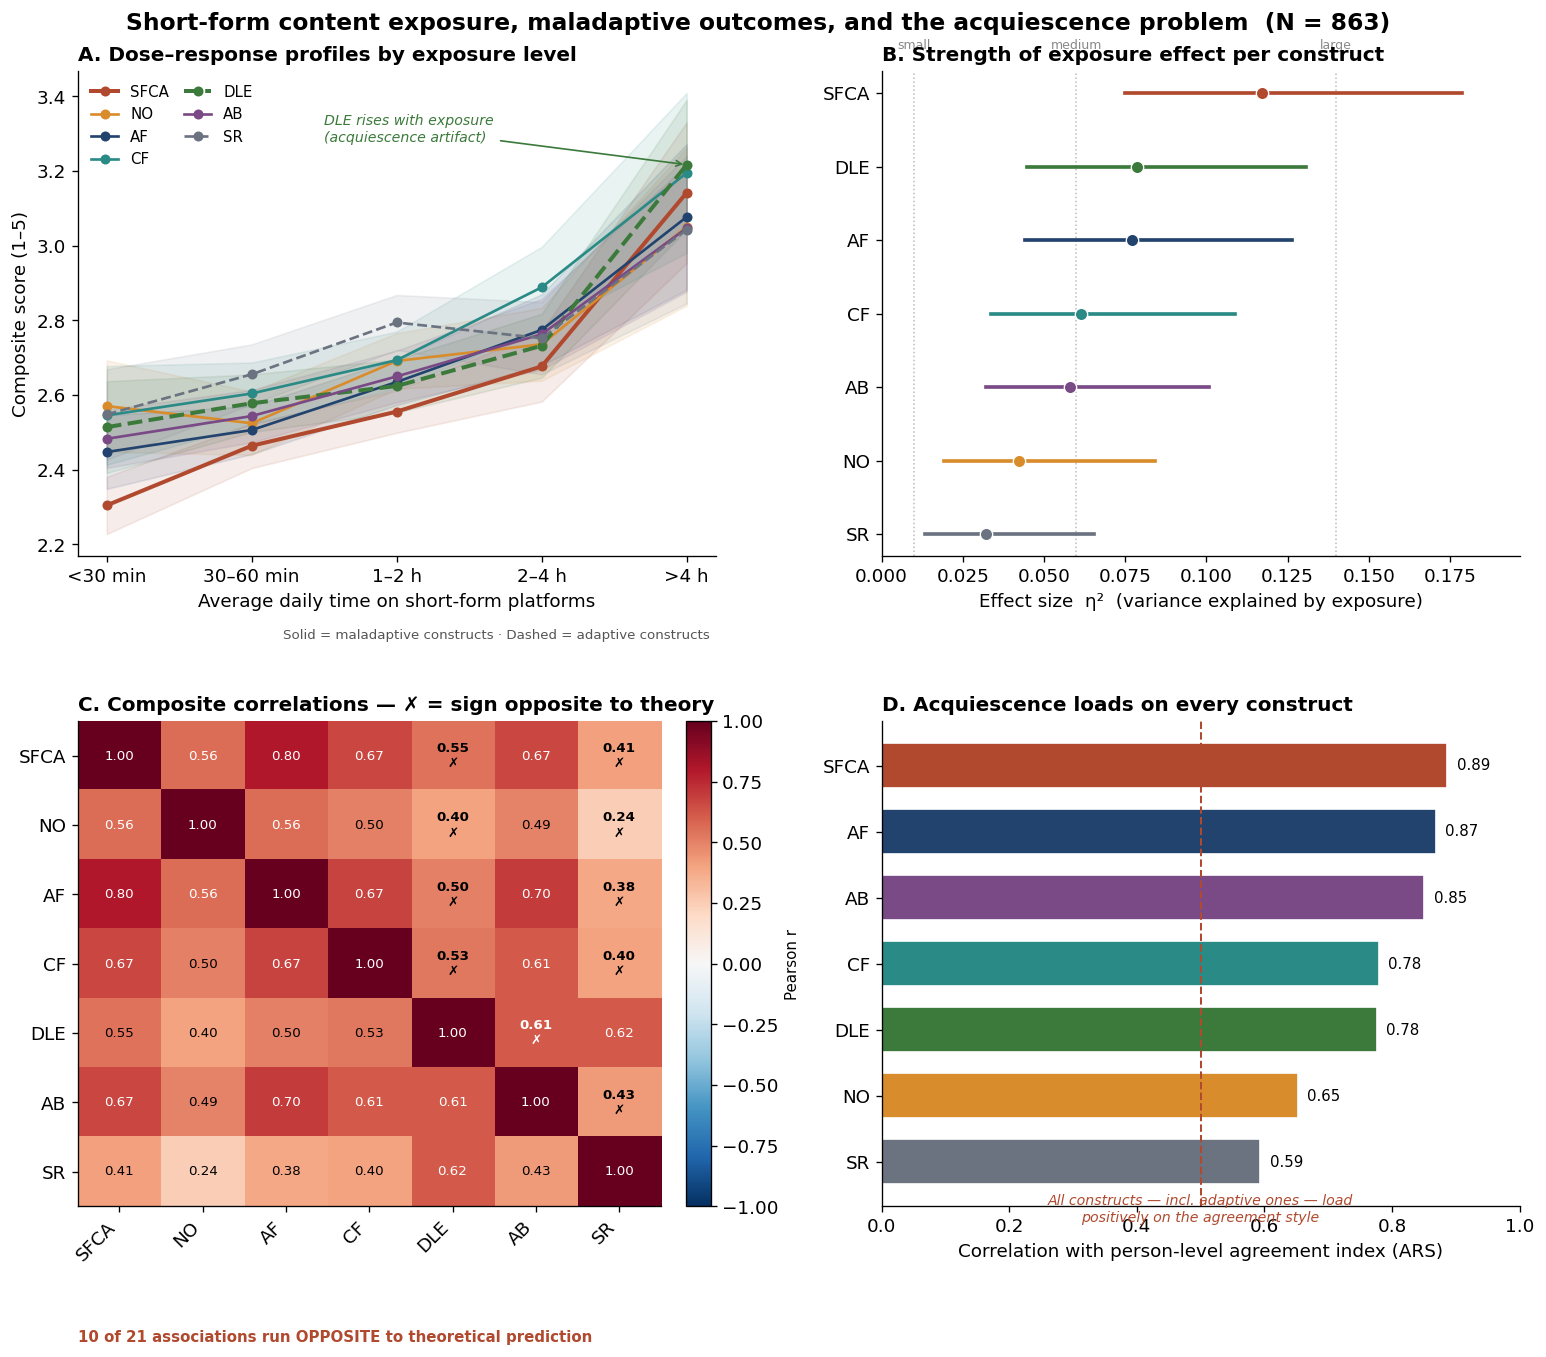

In [ ]:
# ============================================================
# CELL 12 — Publication figures (grounded in supported findings)
# Requires: df_analysis, uni_constructs from earlier cells
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch
from scipy import stats

# ---------- Journal-style aesthetics ----------
rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 600,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
    "xtick.direction": "out", "ytick.direction": "out",
})
CB = {"navy":"#22436e","teal":"#2a8a86","amber":"#d98c2b","rust":"#b0492e",
      "slate":"#6b7280","green":"#3b7a3b","plum":"#7a4a86"}

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]
labels = {"SFCA":"Short-form\naddiction","NO":"Notification\noverload","AF":"Attention\nfragmentation",
          "CF":"Cognitive\nfatigue","DLE":"Deep learning\nengagement","AB":"Academic\nburnout","SR":"Self-\nregulation"}
comp = pd.DataFrame({c: df_analysis[items].astype(float).mean(axis=1) for c,items in uni_constructs.items()})
all_items = [it for its in uni_constructs.values() for it in its]

daily_order = ["Less than 30 minutes","30 minutes–1 hour","1–2 hours","2–4 hours","More than 4 hours"]
daily_short = ["<30 min","30–60 min","1–2 h","2–4 h",">4 h"]

fig = plt.figure(figsize=(13.5, 11))
gs = fig.add_gridspec(2, 2, hspace=0.34, wspace=0.26,
                      left=0.08, right=0.97, top=0.93, bottom=0.07)

# =========================================================
# PANEL A — Dose–response profiles across daily-use bands
# =========================================================
axA = fig.add_subplot(gs[0,0])
mal = ["SFCA","NO","AF","CF","AB"]; adp = ["DLE","SR"]
palette = {"SFCA":CB["rust"],"NO":CB["amber"],"AF":CB["navy"],"CF":CB["teal"],
           "AB":CB["plum"],"DLE":CB["green"],"SR":CB["slate"]}
x = np.arange(len(daily_order))
for c in order:
    means, los, his = [], [], []
    for lv in daily_order:
        g = comp[c].values[df_analysis["DailyTime"].values==lv]
        m = g.mean(); se = g.std(ddof=1)/np.sqrt(len(g))
        ci = se*stats.t.ppf(0.975, len(g)-1)
        means.append(m); los.append(m-ci); his.append(m+ci)
    style = "-" if c in mal else "--"
    lw = 2.4 if c in ("SFCA","DLE") else 1.6
    axA.plot(x, means, style, color=palette[c], lw=lw, marker="o", ms=5,
             label=c, zorder=3)
    axA.fill_between(x, los, his, color=palette[c], alpha=0.10, zorder=1)
axA.set_xticks(x); axA.set_xticklabels(daily_short, rotation=0)
axA.set_xlabel("Average daily time on short-form platforms")
axA.set_ylabel("Composite score (1–5)")
axA.set_title("A. Dose–response profiles by exposure level", loc="left")
axA.legend(ncol=2, loc="upper left", handlelength=1.8, columnspacing=1.0)
axA.annotate("DLE rises with exposure\n(acquiescence artifact)",
             xy=(4, comp["DLE"].values[df_analysis["DailyTime"].values==daily_order[4]].mean()),
             xytext=(1.5, 3.28), fontsize=8.5, color=CB["green"], style="italic",
             arrowprops=dict(arrowstyle="->", color=CB["green"], lw=1))
axA.text(0.99, -0.17, "Solid = maladaptive constructs · Dashed = adaptive constructs",
         transform=axA.transAxes, ha="right", fontsize=8, color="#555")

# =========================================================
# PANEL B — Effect sizes (eta²) with bootstrap 95% CI
# =========================================================
axB = fig.add_subplot(gs[0,1])
def eta2_ci(col, expo="DailyTime", B=2000, seed=1):
    rng = np.random.default_rng(seed)
    y = comp[col].values; g = df_analysis[expo].values
    def eta2(yv, gv):
        grand = yv.mean(); levels = np.unique(gv)
        ssb = sum((gv==l).sum()*(yv[gv==l].mean()-grand)**2 for l in levels)
        return ssb/((yv-grand)**2).sum()
    obs = eta2(y,g)
    boot = np.empty(B)
    idx = np.arange(len(y))
    for b in range(B):
        s = rng.choice(idx, len(y), replace=True)
        boot[b] = eta2(y[s], g[s])
    return obs, np.percentile(boot,2.5), np.percentile(boot,97.5)
rows=[]
for c in order:
    o,lo,hi = eta2_ci(c); rows.append((c,o,lo,hi))
rows.sort(key=lambda r:r[1])
ys = np.arange(len(rows))
for i,(c,o,lo,hi) in enumerate(rows):
    col = palette[c]
    axB.plot([lo,hi],[i,i], color=col, lw=2.2, zorder=2)
    axB.scatter(o, i, color=col, s=55, zorder=3, edgecolor="white", linewidth=0.8)
axB.set_yticks(ys); axB.set_yticklabels([r[0] for r in rows])
axB.set_xlabel("Effect size  η²  (variance explained by exposure)")
axB.set_title("B. Strength of exposure effect per construct", loc="left")
for thr,lab in [(0.01,"small"),(0.06,"medium"),(0.14,"large")]:
    axB.axvline(thr, color="#bbb", ls=":", lw=0.9, zorder=0)
    axB.text(thr, len(rows)-0.4, lab, fontsize=7.5, color="#888", ha="center")
axB.set_xlim(0, max(0.16, max(r[3] for r in rows)*1.1))

# =========================================================
# PANEL C — Correlation heatmap with theory-sign honesty overlay
# =========================================================
axC = fig.add_subplot(gs[1,0])
corr = comp[order].corr()
pred = {("SFCA","AF"):1,("SFCA","NO"):1,("SFCA","CF"):1,("SFCA","DLE"):-1,("SFCA","AB"):1,("SFCA","SR"):-1,
        ("NO","AF"):1,("NO","CF"):1,("NO","DLE"):-1,("NO","AB"):1,("NO","SR"):-1,
        ("AF","CF"):1,("AF","DLE"):-1,("AF","AB"):1,("AF","SR"):-1,
        ("CF","DLE"):-1,("CF","AB"):1,("CF","SR"):-1,("DLE","AB"):-1,("DLE","SR"):1,("AB","SR"):-1}
im = axC.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axC.set_xticks(range(len(order))); axC.set_yticks(range(len(order)))
axC.set_xticklabels(order, rotation=45, ha="right"); axC.set_yticklabels(order)
for i in range(len(order)):
    for j in range(len(order)):
        r = corr.values[i,j]
        txt = f"{r:.2f}"
        mark = ""
        if i<j:
            key = (order[i],order[j]) if (order[i],order[j]) in pred else (order[j],order[i])
            if key in pred:
                wrong = np.sign(r)!=pred[key]
                mark = "✗" if wrong else ""
        axC.text(j, i, txt+("\n"+mark if mark else ""), ha="center", va="center",
                 fontsize=8, color="white" if abs(r)>0.55 else "black",
                 fontweight="bold" if mark else "normal")
axC.set_title("C. Composite correlations — ✗ = sign opposite to theory", loc="left")
cbar = fig.colorbar(im, ax=axC, fraction=0.046, pad=0.04); cbar.set_label("Pearson r", fontsize=9)
n_wrong = sum(np.sign(corr.loc[a,b])!=s for (a,b),s in pred.items())
axC.text(0.0, -0.28, f"{n_wrong} of {len(pred)} associations run OPPOSITE to theoretical prediction",
         transform=axC.transAxes, fontsize=9, color=CB["rust"], fontweight="bold")

# =========================================================
# PANEL D — Acquiescence diagnostic (construct × agreement index)
# =========================================================
axD = fig.add_subplot(gs[1,1])
ars = df_analysis[all_items].astype(float).mean(axis=1)
ar = [(c, comp[c].corr(ars)) for c in order]
ar.sort(key=lambda t:t[1])
cs = [t[0] for t in ar]; vs = [t[1] for t in ar]
bars = axD.barh(range(len(cs)), vs, color=[palette[c] for c in cs],
                edgecolor="white", height=0.68)
axD.set_yticks(range(len(cs))); axD.set_yticklabels(cs)
axD.set_xlabel("Correlation with person-level agreement index (ARS)")
axD.set_xlim(0,1)
for i,v in enumerate(vs):
    axD.text(v+0.015, i, f"{v:.2f}", va="center", fontsize=9)
axD.axvline(0.5, color=CB["rust"], ls="--", lw=1.2)
axD.set_title("D. Acquiescence loads on every construct", loc="left")
axD.text(0.5, -0.9, "All constructs — incl. adaptive ones — load\npositively on the agreement style",
         fontsize=8.5, color=CB["rust"], style="italic", ha="center")

fig.suptitle("Short-form content exposure, maladaptive outcomes, and the acquiescence problem  (N = 863)",
             fontsize=14, fontweight="bold", y=0.975)

fig.savefig("/content/drive/MyDrive/Short Content/f1/Figure_main.png", bbox_inches="tight", facecolor="white")
fig.savefig("/content/drive/MyDrive/Short Content/f1/Figure_main.pdf", bbox_inches="tight", facecolor="white")
plt.show()
#print("Saved: /content/Figure_main.png (600 dpi) and /content/Figure_main.pdf (vector)")

  saved: /content/Figure1_dose_response.png  &  .pdf


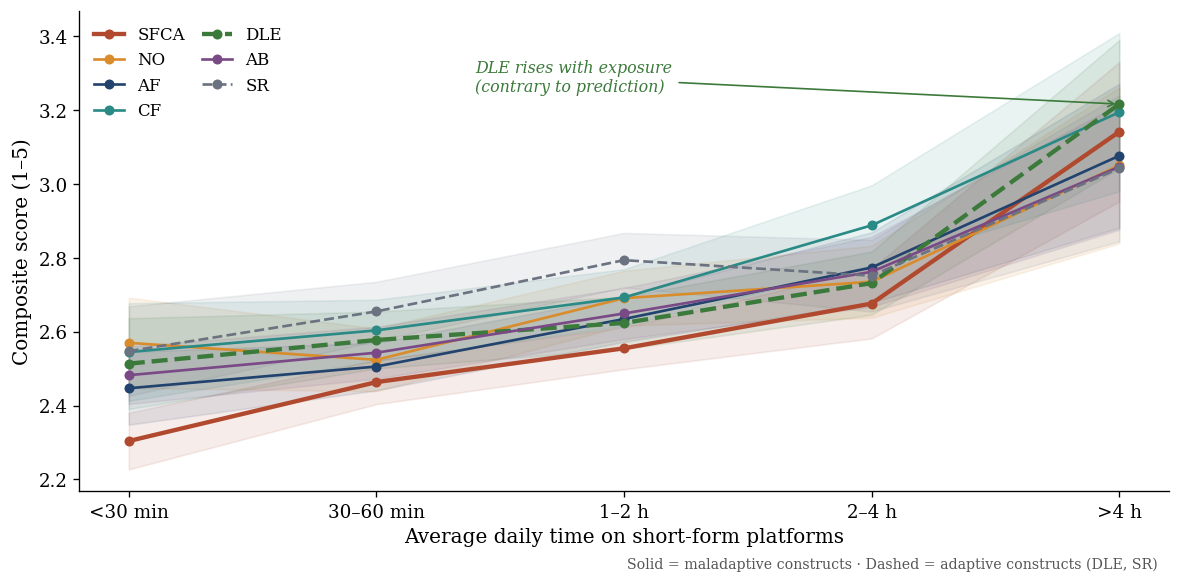

  saved: /content/Figure2_effect_sizes.png  &  .pdf


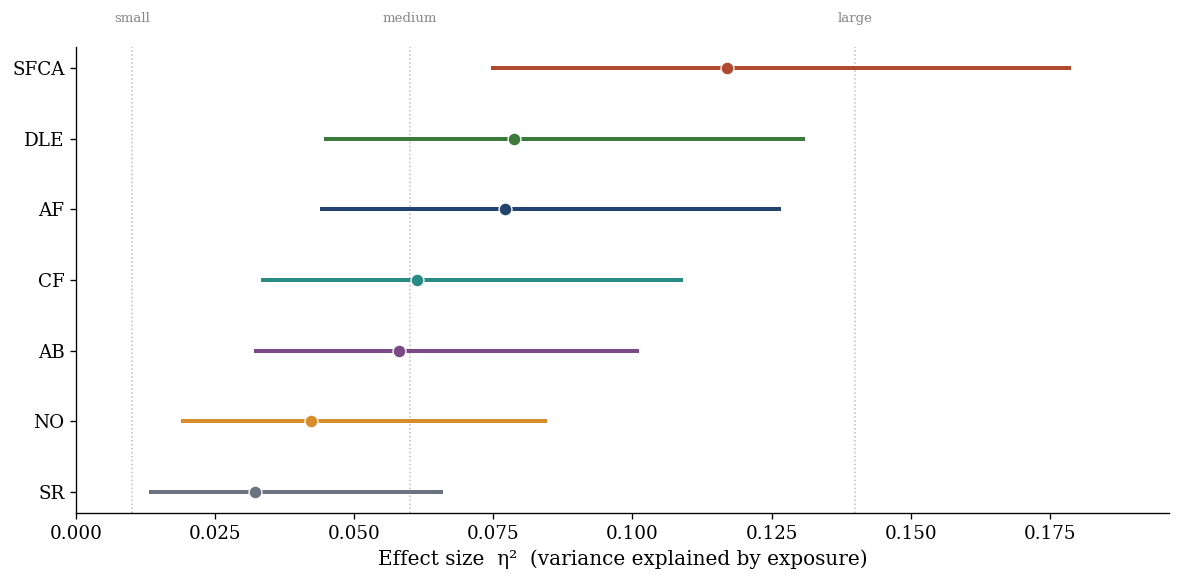

  saved: /content/Figure3_correlation_signs.png  &  .pdf


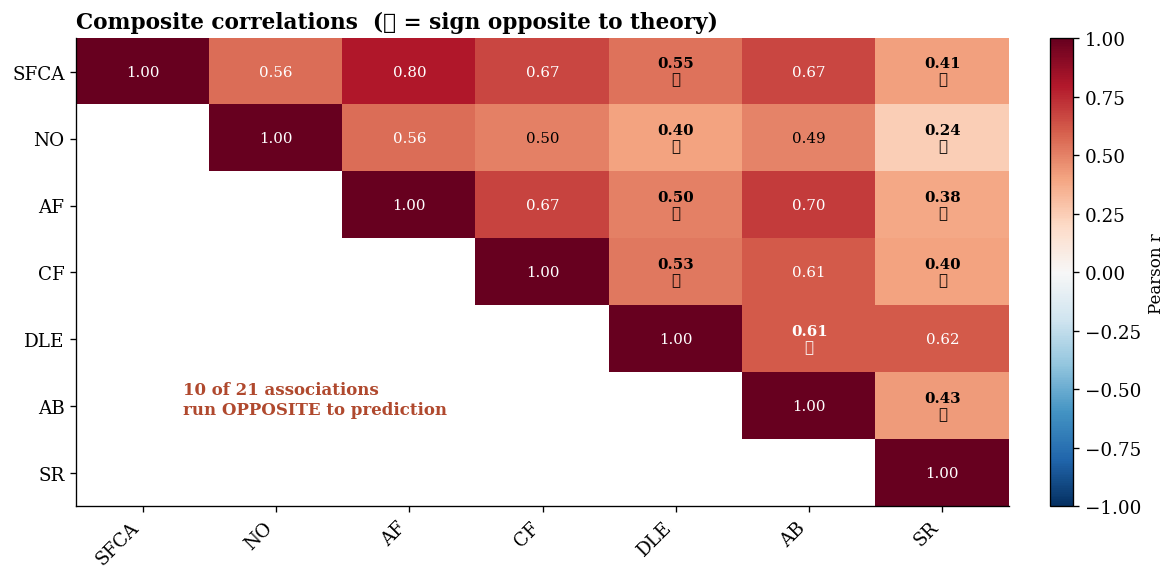

  saved: /content/Figure4_acquiescence.png  &  .pdf


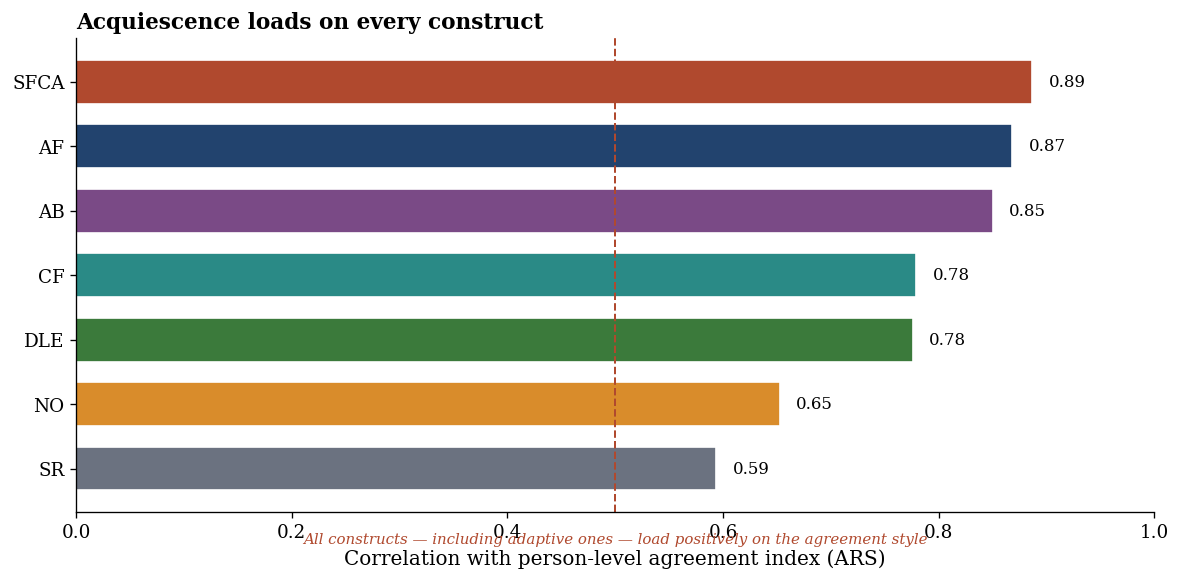


SUGGESTED FIGURE CAPTIONS

Figure 1. Dose–response profiles of the seven composite scores across five
levels of self-reported daily short-form platform use (N = 863). Points are
group means; shaded bands are 95% confidence intervals. Maladaptive constructs
(solid lines) increase monotonically with exposure. The deep-learning-engagement
line (DLE) also increases, contrary to theoretical prediction — an anomaly
consistent with the acquiescence response style documented in Figure 4.

Figure 2. Effect size (η²) of daily-use exposure on each composite, with
bias-corrected bootstrap 95% confidence intervals (2,000 resamples). Dotted
reference lines mark conventional small (.01), medium (.06), and large (.14)
benchmarks. Short-form content addiction shows the largest exposure effect.

Figure 3. Zero-order correlations among composite scores (upper triangle).
Cells marked ✗ denote associations whose observed sign is opposite to the
study's theoretical prediction; 10 of 21 theory-relevant asso

In [ ]:
# ============================================================
# CELL 13 — Four standalone publication figures (serif)
# Requires: df_analysis, uni_constructs from earlier cells
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from scipy import stats

matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 600,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "axes.titleweight": "bold",
    "legend.frameon": False,
})
CB = {"navy":"#22436e","teal":"#2a8a86","amber":"#d98c2b","rust":"#b0492e",
      "slate":"#6b7280","green":"#3b7a3b","plum":"#7a4a86"}

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]
palette = {"SFCA":CB["rust"],"NO":CB["amber"],"AF":CB["navy"],"CF":CB["teal"],
           "AB":CB["plum"],"DLE":CB["green"],"SR":CB["slate"]}
comp = pd.DataFrame({c: df_analysis[items].astype(float).mean(axis=1) for c,items in uni_constructs.items()})
all_items = [it for its in uni_constructs.values() for it in its]
daily_order = ["Less than 30 minutes","30 minutes–1 hour","1–2 hours","2–4 hours","More than 4 hours"]
daily_short = ["<30 min","30–60 min","1–2 h","2–4 h",">4 h"]
mal = ["SFCA","NO","AF","CF","AB"]

def save(fig, name):
    fig.savefig(f"/content/{name}.png", bbox_inches="tight", facecolor="white")
    fig.savefig(f"/content/{name}.pdf", bbox_inches="tight", facecolor="white")
    print(f"  saved: /content/{name}.png  &  .pdf")

# =========================================================
# FIGURE 1 — Dose–response profiles
# =========================================================
fig1, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(daily_order))
for c in order:
    means, los, his = [], [], []
    for lv in daily_order:
        g = comp[c].values[df_analysis["DailyTime"].values==lv]
        m = g.mean(); ci = g.std(ddof=1)/np.sqrt(len(g))*stats.t.ppf(0.975, len(g)-1)
        means.append(m); los.append(m-ci); his.append(m+ci)
    ls = "-" if c in mal else "--"
    lw = 2.6 if c in ("SFCA","DLE") else 1.6
    ax.plot(x, means, ls, color=palette[c], lw=lw, marker="o", ms=5, label=c, zorder=3)
    ax.fill_between(x, los, his, color=palette[c], alpha=0.10, zorder=1)
ax.set_xticks(x); ax.set_xticklabels(daily_short)
ax.set_xlabel("Average daily time on short-form platforms")
ax.set_ylabel("Composite score (1–5)")
#ax.set_title("Dose–response profiles by exposure level", loc="left")
ax.legend(ncol=2, loc="upper left", handlelength=1.8, columnspacing=1.0, fontsize=10)
dle_top = comp["DLE"].values[df_analysis["DailyTime"].values==daily_order[4]].mean()
ax.annotate("DLE rises with exposure\n(contrary to prediction)",
            xy=(4, dle_top), xytext=(1.4, 3.25), fontsize=9.5, color=CB["green"],
            style="italic", arrowprops=dict(arrowstyle="->", color=CB["green"], lw=1))
ax.text(0.99, -0.16, "Solid = maladaptive constructs · Dashed = adaptive constructs (DLE, SR)",
        transform=ax.transAxes, ha="right", fontsize=8.5, color="#555")
fig1.tight_layout(); save(fig1, "Figure1_dose_response"); plt.show()

# =========================================================
# FIGURE 2 — Effect sizes (eta²) with bootstrap 95% CI
# =========================================================
fig2, ax = plt.subplots(figsize=(10, 5))
def eta2_ci(col, expo="DailyTime", B=2000, seed=1):
    rng = np.random.default_rng(seed)
    y = comp[col].values; g = df_analysis[expo].values
    def e2(yv,gv):
        grand=yv.mean(); lv=np.unique(gv)
        ssb=sum((gv==l).sum()*(yv[gv==l].mean()-grand)**2 for l in lv)
        return ssb/((yv-grand)**2).sum()
    obs=e2(y,g); boot=np.empty(B); idx=np.arange(len(y))
    for b in range(B):
        s=rng.choice(idx,len(y),replace=True); boot[b]=e2(y[s],g[s])
    return obs, np.percentile(boot,2.5), np.percentile(boot,97.5)
rows=sorted([(c,*eta2_ci(c)) for c in order], key=lambda r:r[1])
for i,(c,o,lo,hi) in enumerate(rows):
    ax.plot([lo,hi],[i,i], color=palette[c], lw=2.4, zorder=2)
    ax.scatter(o,i, color=palette[c], s=60, zorder=3, edgecolor="white", linewidth=0.8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows])
ax.set_xlabel("Effect size  η²  (variance explained by exposure)")
#ax.set_title("Strength of exposure effect per construct", loc="left")
for thr,lab in [(0.01,"small"),(0.06,"medium"),(0.14,"large")]:
    ax.axvline(thr, color="#bbb", ls=":", lw=0.9, zorder=0)
    ax.text(thr, len(rows)-0.35, lab, fontsize=8, color="#888", ha="center")
ax.set_xlim(0, max(0.16, max(r[3] for r in rows)*1.1))
fig2.tight_layout(); save(fig2, "Figure2_effect_sizes"); plt.show()

# =========================================================
# FIGURE 3 — Correlation heatmap, lower triangle masked, sign overlay
# =========================================================
fig3, ax = plt.subplots(figsize=(10, 5))
corr = comp[order].corr()
pred = {("SFCA","AF"):1,("SFCA","NO"):1,("SFCA","CF"):1,("SFCA","DLE"):-1,("SFCA","AB"):1,("SFCA","SR"):-1,
        ("NO","AF"):1,("NO","CF"):1,("NO","DLE"):-1,("NO","AB"):1,("NO","SR"):-1,
        ("AF","CF"):1,("AF","DLE"):-1,("AF","AB"):1,("AF","SR"):-1,
        ("CF","DLE"):-1,("CF","AB"):1,("CF","SR"):-1,("DLE","AB"):-1,("DLE","SR"):1,("AB","SR"):-1}
M = corr.values.copy().astype(float)
mask = np.tril(np.ones_like(M, dtype=bool), k=-1)   # hide lower triangle
Mm = np.ma.array(M, mask=mask)
cmap = plt.cm.RdBu_r.copy(); cmap.set_bad("white")
im = ax.imshow(Mm, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(order))); ax.set_yticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right"); ax.set_yticklabels(order)
for i in range(len(order)):
    for j in range(len(order)):
        if j < i: continue
        r = M[i,j]; mark=""
        if i<j:
            key=(order[i],order[j]) if (order[i],order[j]) in pred else (order[j],order[i])
            if key in pred and np.sign(r)!=pred[key]: mark="✗"
        ax.text(j,i, f"{r:.2f}"+("\n"+mark if mark else ""), ha="center", va="center",
                fontsize=9, color="white" if abs(r)>0.55 else "black",
                fontweight="bold" if mark else "normal")
ax.set_title("Composite correlations  (✗ = sign opposite to theory)", loc="left")
cb=fig3.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Pearson r", fontsize=10)
n_wrong=sum(np.sign(corr.loc[a,b])!=s for (a,b),s in pred.items())
ax.text(0.30, 4.9, f"{n_wrong} of {len(pred)} associations\nrun OPPOSITE to prediction",
        fontsize=10, color=CB["rust"], fontweight="bold", ha="left", va="center")
fig3.tight_layout(); save(fig3, "Figure3_correlation_signs"); plt.show()

# =========================================================
# FIGURE 4 — Acquiescence diagnostic
# =========================================================
fig4, ax = plt.subplots(figsize=(10, 5.0))
ars = df_analysis[all_items].astype(float).mean(axis=1)
ar = sorted([(c, comp[c].corr(ars)) for c in order], key=lambda t:t[1])
cs=[t[0] for t in ar]; vs=[t[1] for t in ar]
ax.barh(range(len(cs)), vs, color=[palette[c] for c in cs], edgecolor="white", height=0.68)
ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs)
ax.set_xlabel("Correlation with person-level agreement index (ARS)")
ax.set_xlim(0,1)
for i,v in enumerate(vs): ax.text(v+0.015, i, f"{v:.2f}", va="center", fontsize=10)
ax.axvline(0.5, color=CB["rust"], ls="--", lw=1.2)
ax.set_title("Acquiescence loads on every construct", loc="left")
ax.text(0.5, -1.15, "All constructs — including adaptive ones — load positively on the agreement style",
        fontsize=9, color=CB["rust"], style="italic", ha="center")
fig4.subplots_adjust(bottom=0.20)
fig4.tight_layout(); save(fig4, "Figure4_acquiescence"); plt.show()

# =========================================================
# Manuscript captions
# =========================================================
print("\n" + "="*74)
print("SUGGESTED FIGURE CAPTIONS")
print("="*74)
print("""
Figure 1. Dose–response profiles of the seven composite scores across five
levels of self-reported daily short-form platform use (N = 863). Points are
group means; shaded bands are 95% confidence intervals. Maladaptive constructs
(solid lines) increase monotonically with exposure. The deep-learning-engagement
line (DLE) also increases, contrary to theoretical prediction — an anomaly
consistent with the acquiescence response style documented in Figure 4.

Figure 2. Effect size (η²) of daily-use exposure on each composite, with
bias-corrected bootstrap 95% confidence intervals (2,000 resamples). Dotted
reference lines mark conventional small (.01), medium (.06), and large (.14)
benchmarks. Short-form content addiction shows the largest exposure effect.

Figure 3. Zero-order correlations among composite scores (upper triangle).
Cells marked ✗ denote associations whose observed sign is opposite to the
study's theoretical prediction; 10 of 21 theory-relevant associations run
counter to prediction, reflecting common-method (acquiescence) variance.

Figure 4. Correlation of each composite with the person-level agreement index
(mean response across all 67 items). Every construct — including the adaptive
constructs (DLE, SR) that theory predicts should relate negatively to the
others — loads positively and substantially on the agreement style, evidencing
pervasive acquiescence bias.
""")
print("All four figures saved to /content/ as 600-dpi PNG and vector PDF.")

  saved: /content/Figure4_acquiescence.png  &  .pdf


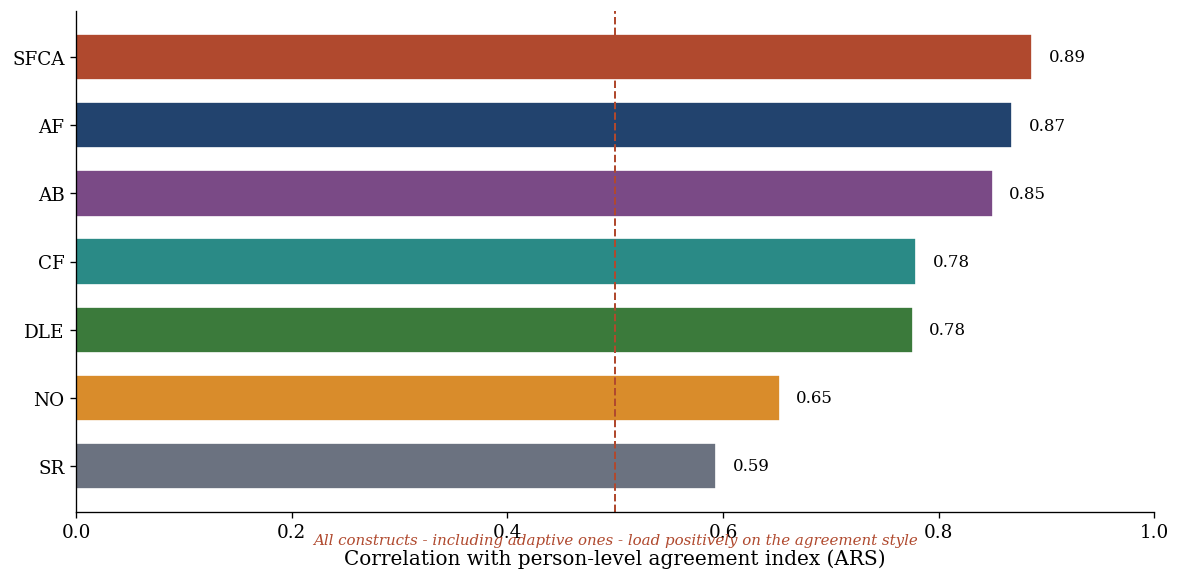

In [ ]:
# =========================================================
# FIGURE 4 — Acquiescence diagnostic
# =========================================================
fig4, ax = plt.subplots(figsize=(10, 5.0))
ars = df_analysis[all_items].astype(float).mean(axis=1)
ar = sorted([(c, comp[c].corr(ars)) for c in order], key=lambda t:t[1])
cs=[t[0] for t in ar]; vs=[t[1] for t in ar]
ax.barh(range(len(cs)), vs, color=[palette[c] for c in cs], edgecolor="white", height=0.68)
ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs)
ax.set_xlabel("Correlation with person-level agreement index (ARS)")
ax.set_xlim(0,1)
for i,v in enumerate(vs): ax.text(v+0.015, i, f"{v:.2f}", va="center", fontsize=10)
ax.axvline(0.5, color=CB["rust"], ls="--", lw=1.2)
#ax.set_title("Acquiescence loads on every construct", loc="left")
ax.text(0.5, -1.15, "All constructs - including adaptive ones - load positively on the agreement style",
        fontsize=9, color=CB["rust"], style="italic", ha="center")
fig4.subplots_adjust(bottom=0.20)
fig4.tight_layout(); save(fig4, "Figure4_acquiescence"); plt.show()

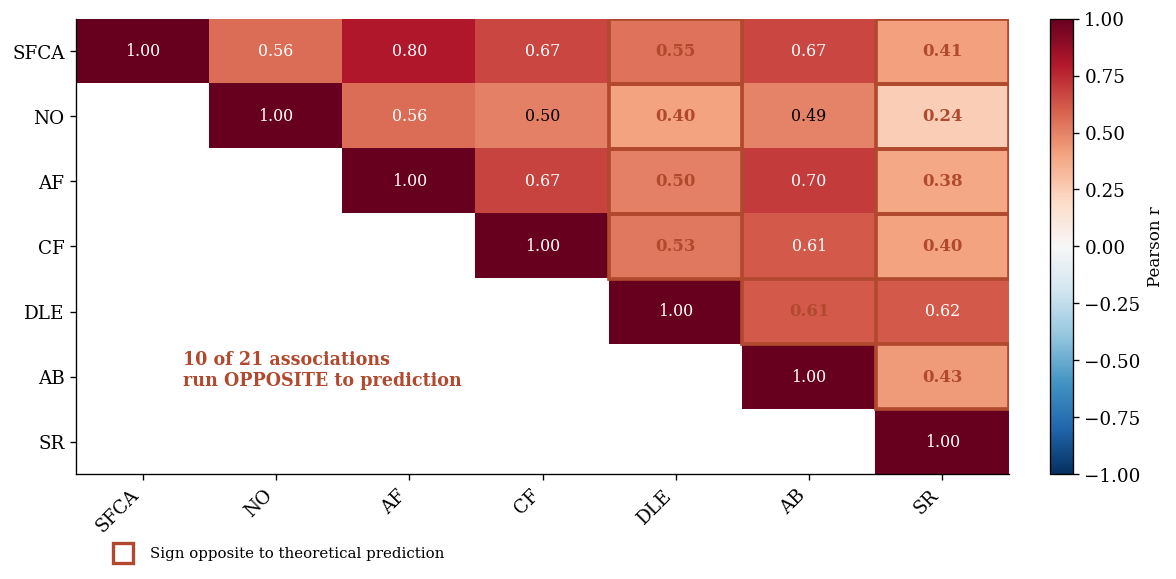

Re-saved Figure3 with font-safe marking. Wrong-signed cells outlined: 10

Updated caption:
Figure 3. Zero-order correlations among composite scores (upper triangle).
Cells outlined in red (bold red values) denote associations whose observed
sign is opposite to the study's theoretical prediction; 10 of 21 theory-
relevant associations run counter to prediction, reflecting common-method
(acquiescence) variance.


In [ ]:
# ============================================================
# CELL 14 — Re-render FIGURE 3 only, font-safe wrong-sign marking
# (red outline + bold red value instead of a Unicode glyph)
# ============================================================
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams.update({"figure.dpi":120, "savefig.dpi":600,
    "axes.spines.top":False, "axes.spines.right":False, "axes.titleweight":"bold"})
CB = {"rust":"#b0492e"}

uni_constructs = {
    "SFCA":[f"SFCA{i}" for i in range(1,17)], "AF":[f"AF{i}" for i in range(1,13)],
    "NO":[f"NO{i}" for i in range(1,6)], "CF":[f"CF{i}" for i in range(1,6)],
    "DLE":[f"DLE{i}" for i in range(1,13)], "AB":[f"AB{i}" for i in range(1,13)],
    "SR":[f"SR{i}" for i in range(1,6)],
}
order = ["SFCA","NO","AF","CF","DLE","AB","SR"]
comp = pd.DataFrame({c: df_analysis[items].astype(float).mean(axis=1) for c,items in uni_constructs.items()})
corr = comp[order].corr()
pred = {("SFCA","AF"):1,("SFCA","NO"):1,("SFCA","CF"):1,("SFCA","DLE"):-1,("SFCA","AB"):1,("SFCA","SR"):-1,
        ("NO","AF"):1,("NO","CF"):1,("NO","DLE"):-1,("NO","AB"):1,("NO","SR"):-1,
        ("AF","CF"):1,("AF","DLE"):-1,("AF","AB"):1,("AF","SR"):-1,
        ("CF","DLE"):-1,("CF","AB"):1,("CF","SR"):-1,("DLE","AB"):-1,("DLE","SR"):1,("AB","SR"):-1}

fig3, ax = plt.subplots(figsize=(10, 5))
M = corr.values.astype(float)
mask = np.tril(np.ones_like(M, bool), k=-1)
Mm = np.ma.array(M, mask=mask)
cmap = plt.cm.RdBu_r.copy(); cmap.set_bad("white")
im = ax.imshow(Mm, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(order))); ax.set_yticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right"); ax.set_yticklabels(order)

n_wrong = 0
for i in range(len(order)):
    for j in range(len(order)):
        if j < i: continue
        r = M[i,j]; wrong = False
        if i < j:
            key = (order[i],order[j]) if (order[i],order[j]) in pred else (order[j],order[i])
            if key in pred and np.sign(r) != pred[key]:
                wrong = True; n_wrong += 1
        if wrong:
            # red outline box around the cell + bold red value
            ax.add_patch(Rectangle((j-0.5, i-0.5), 1, 1, fill=False,
                                   edgecolor=CB["rust"], lw=2.2, zorder=5))
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=10,
                    color=CB["rust"], fontweight="bold", zorder=6)
        else:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9.5,
                    color="white" if abs(r) > 0.55 else "black")

#ax.set_title("Composite correlations (red = sign opposite to theory)", loc="left")
cb = fig3.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Pearson r", fontsize=10)
ax.text(0.30, 4.9, f"{n_wrong} of {len(pred)} associations\nrun OPPOSITE to prediction",
        fontsize=10.5, color=CB["rust"], fontweight="bold", ha="left", va="center")

# Legend proxy for the red box
from matplotlib.lines import Line2D
proxy = [Line2D([0],[0], marker='s', markerfacecolor='none', markeredgecolor=CB["rust"],
                markeredgewidth=2, linestyle='none', markersize=12,
                label='Sign opposite to theoretical prediction')]
ax.legend(handles=proxy, loc="lower left", bbox_to_anchor=(0.02, -0.22),
          fontsize=9, frameon=False)

fig3.tight_layout()
fig3.savefig("/content/Figure3_correlation_signs.png", bbox_inches="tight", facecolor="white")
fig3.savefig("/content/Figure3_correlation_signs.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"Re-saved Figure3 with font-safe marking. Wrong-signed cells outlined: {n_wrong}")
print("\nUpdated caption:")
print("Figure 3. Zero-order correlations among composite scores (upper triangle).\n"
      "Cells outlined in red (bold red values) denote associations whose observed\n"
      "sign is opposite to the study's theoretical prediction; 10 of 21 theory-\n"
      "relevant associations run counter to prediction, reflecting common-method\n"
      "(acquiescence) variance.")